# 종합 통계 실습

## 비즈니스 시나리오

> 여러분은 식품·와인 유통 기업 **FreshCart**의 데이터 분석팀 인턴입니다. \
> 마케팅팀이 6차례 캠페인을 진행했지만 수락률이 낮아 경영진이 우려하고 있습니다. \
> 고객 데이터를 분석하여 **다음 캠페인의 집중 공략 전략**을 수립해 주세요.

---

| Part | 주제 | 핵심 질문 |
|------|------|-----------|
| **Part 0** | 데이터 전처리 | (코드 제공) |
| **Part 1** | 탐색적 데이터 분석 | 고객은 누구인가? |
| **Part 2** | 확률분포 모델링 | 고객 행동은 어떤 패턴을 따르는가? |
| **Part 3** | 추정과 가설검정 | 고소득 고객과 저소득 고객의 소비는 다른가? |
| **Part 4** | 고급 검정 | 교육, 결혼, 캠페인 반응의 관계는? |
| **Part 5** | 상관분석 / 비율 비교 | 변수 간 관계를 파악하고, 캠페인 효과를 검증할 수 있는가? |
| **Challenge** | 종합 분석 보고서 | 다음 캠페인 타겟은 누구인가? |

### 데이터 셋 개요

| 항목 | 내용 |
|------|------|
| **출처** | Kaggle |
| **URL** | https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis |
| **크기** | 약 2,240행 × 29열 |
| **파일명** | `marketing_campaign.csv` |
| **도메인** | 식품·와인 유통 기업 |

**설명:** 고객 성격 분석은 기업의 이상적인 고객을 심층 분석하는 방법론이다. 고객 세그먼트별 니즈·행동·관심사를 파악해 제품 및 마케팅을 최적화하는 데 활용한다.

---

### 변수 목록

#### 고객 정보

| # | 변수명 | 설명 |
|---|--------|------|
| 1 | `ID` | 고객 고유 식별자 |
| 2 | `Year_Birth` | 고객 출생연도 |
| 3 | `Education` | 최종 학력 |
| 4 | `Marital_Status` | 결혼 상태 |
| 5 | `Income` | 연간 가구 소득 |
| 6 | `Kidhome` | 가구 내 어린 자녀 수 |
| 7 | `Teenhome` | 가구 내 십대 자녀 수 |
| 8 | `Dt_Customer` | 고객 등록일 |
| 9 | `Recency` | 마지막 구매 이후 경과 일수 |

---

#### 소비 패턴 — 최근 2년간 지출 금액

| # | 변수명 | 설명 |
|---|--------|------|
| 10 | `MntWines` | 와인 지출 금액 |
| 11 | `MntFruits` | 과일 지출 금액 |
| 12 | `MntMeatProducts` | 육류 지출 금액 |
| 13 | `MntFishProducts` | 생선 지출 금액 |
| 14 | `MntSweetProducts` | 과자·디저트 지출 금액 |
| 15 | `MntGoldProds` | 골드 지출 금액 |

---

#### 캠페인 반응

| # | 변수명 | 설명 |
|---|--------|------|
| 16 | `NumDealsPurchases` | 할인 적용 구매 횟수 |
| 17 | `NumWebPurchases` | 웹사이트를 통한 구매 횟수 |
| 18 | `NumCatalogPurchases` | 카탈로그를 통한 구매 횟수 |
| 19 | `NumStorePurchases` | 오프라인 매장 구매 횟수 |
| 20 | `NumWebVisitsMonth` | 최근 한 달간 웹사이트 방문 횟수 |
| 21 | `AcceptedCmp3` | 3차 캠페인 제안 수락 여부 (1=수락, 0=거절) |
| 22 | `AcceptedCmp4` | 4차 캠페인 제안 수락 여부 |
| 23 | `AcceptedCmp5` | 5차 캠페인 제안 수락 여부 |
| 24 | `AcceptedCmp1` | 1차 캠페인 제안 수락 여부 |
| 25 | `AcceptedCmp2` | 2차 캠페인 제안 수락 여부 |
| 26 | `Complain` | 최근 2년 내 불만 제기 여부 (1=있음, 0=없음) |
| 27 | `Z_CostContact` | 상수값 3 — 캠페인 1회당 연락 비용 |
| 28 | `Z_Revenue` | 상수값 11 — 캠페인 성공 시 수익 |
| 29 | `Response` | 최종 캠페인 제안 수락 여부 **(타깃 변수)** |

In [596]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import trim_mean
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import (
    proportions_ztest, proportion_confint, proportion_effectsize
)
from statsmodels.stats.power import NormalIndPower, TTestIndPower
import pingouin as pg
import warnings
import platform

warnings.filterwarnings('ignore')

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

COLORS = {
    'blue': '#3B82F6', 'indigo': '#6366F1', 'violet': '#8B5CF6',
    'teal': '#14B8A6', 'emerald': '#10B981', 'amber': '#F59E0B',
    'rose': '#F43F5E', 'red': '#EF4444', 'slate': '#64748B',
    'sky': '#0EA5E9', 'purple': '#A855F7', 'lime': '#84CC16',
}

---
## Part 0: 데이터 전처리 (코드 제공)

아래 코드를 실행하여 분석에 사용할 데이터프레임 `df`를 준비합니다.
모든 파생변수가 생성되고 이상치가 제거된 상태에서 Part 1부터 분석을 시작합니다.

### 0-1. 데이터 로드 및 결측치 처리

In [597]:
df = pd.read_csv('data/marketing_campaign.csv', sep='\t')
print(f"원본 데이터: {df.shape[0]}행 × {df.shape[1]}열")
print(f"Income 결측치: {df['Income'].isnull().sum()}개")

df['Income'] = df['Income'].fillna(df['Income'].median())
print(f"→ Income 중앙값({df['Income'].median():,.0f})으로 대치 완료")

원본 데이터: 2240행 × 29열
Income 결측치: 24개
→ Income 중앙값(51,382)으로 대치 완료


### 0-2. 파생변수 생성

In [598]:
spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts',
                 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
purchase_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
                 'AcceptedCmp4', 'AcceptedCmp5', 'Response']

df['Age'] = 2024 - df['Year_Birth']
df['Total_Spending'] = df[spending_cols].sum(axis=1)
df['Total_Purchases'] = df[purchase_cols].sum(axis=1)
df['Total_Accepted'] = df[campaign_cols].sum(axis=1)
df['Has_Children'] = (df['Kidhome'] + df['Teenhome']) > 0
df['Income_Group'] = pd.qcut(df['Income'], 3, labels=['Low', 'Mid', 'High'])

bins = [0, 39, 49, 59, 200]
labels_age = ['30대 이하', '40대', '50대', '60대 이상']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels_age)

edu_map = {'Basic': 'Undergraduate', '2n Cycle': 'Undergraduate',
           'Graduation': 'Graduate', 'Master': 'Postgraduate', 'PhD': 'Postgraduate'}
df['Education_Group'] = df['Education'].map(edu_map)

marital_map = {'Married': 'Together', 'Together': 'Together',
               'Single': 'Single', 'Divorced': 'Single', 'Widow': 'Single',
               'Alone': 'Single', 'Absurd': 'Single', 'YOLO': 'Single'}
df['Marital_Group'] = df['Marital_Status'].map(marital_map)

df['Campaign_Response'] = df['Total_Accepted'] > 0

df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
reference_date = df['Dt_Customer'].max()
df['Customer_Days'] = (reference_date - df['Dt_Customer']).dt.days

print("파생변수 생성 완료:")
for col in ['Age', 'Total_Spending', 'Total_Purchases', 'Total_Accepted',
            'Has_Children', 'Income_Group', 'Age_Group', 'Education_Group',
            'Marital_Group', 'Campaign_Response', 'Customer_Days']:
    print(f"  - {col}: {df[col].dtype}")

파생변수 생성 완료:
  - Age: int64
  - Total_Spending: int64
  - Total_Purchases: int64
  - Total_Accepted: int64
  - Has_Children: bool
  - Income_Group: category
  - Age_Group: category
  - Education_Group: str
  - Marital_Group: str
  - Campaign_Response: bool
  - Customer_Days: int64


### 0-3. 이상치 제거

In [599]:
n_before = len(df)
df = df[(df['Age'] <= 100) & (df['Income'] <= 200000)].copy()
n_after = len(df)
print(f"이상치 제거: {n_before}행 → {n_after}행 ({n_before - n_after}행 제거)")
print(f"\n최종 데이터 요약:")
print(f"  Age 범위: {df['Age'].min()} ~ {df['Age'].max()}")
print(f"  Income 범위: {df['Income'].min():,.0f} ~ {df['Income'].max():,.0f}")
print(f"\n데이터 준비가 완료되었습니다. Part 1부터 분석을 시작하세요!")

이상치 제거: 2240행 → 2236행 (4행 제거)

최종 데이터 요약:
  Age 범위: 28 ~ 84
  Income 범위: 1,730 ~ 162,397

데이터 준비가 완료되었습니다. Part 1부터 분석을 시작하세요!


---
## Part 1: 탐색적 데이터 분석 — "고객은 누구인가?"

기술통계량과 시각화를 통해 FreshCart 고객의 특성을 파악합니다.

### 문제 1-1. 중심경향과 산포도

`Income`, `Total_Spending`, `Age` 세 변수에 대해 다음을 계산하세요.

| 중심경향 | 산포도 |
|----------|--------|
| 평균(mean) | 분산(variance) |
| 중앙값(median) | 표준편차(std) |
| 최빈값(mode) | 사분위범위(IQR) |
| 5% 절사평균(trimmed mean) | 변동계수(CV) |

In [600]:
# TODO 1-1(a): Income, Total_Spending, Age의 중심경향 — 평균, 중앙값, 최빈값, 5% 절사평균
cols = ["Income", "Total_Spending", "Age"]
summary1 = pd.DataFrame(index=cols)
summary1["Mean"] = df[cols].mean()
summary1["Median"] = df[cols].median()
summary1["Mode"] = df[cols].mode().iloc[0]
summary1["Trimmed Mean(5%)"] = df[cols].apply(
    lambda x: trim_mean(x, 0.05)
)
summary1.round(2)

,Mean,Median,Mode,Trimmed Mean(5%)
Income,51952.61,51381.5,51381.5,51740.15
Total_Spending,605.99,396.5,46.0,561.12
Age,55.10,54.0,48.0,55.07


In [601]:
# TODO 1-1(b): Income, Total_Spending, Age의 산포도 — 분산(ddof=1), 표준편차, IQR, CV(%)
summary2 = pd.DataFrame(index=cols)
summary2["Variance(ddof=1)"] = df[cols].var(ddof=1)
summary2["Std"] = df[cols].std(ddof=1)
summary2["IQR"] = df[cols].quantile(0.75) - df[cols].quantile(0.25)
summary2["CV(%)"] = df[cols].std(ddof=1) / df[cols].mean()

summary2.round(2)

,Variance(ddof=1),Std,IQR,CV(%)
Income,4.584509e+08,21411.47,32773.25,0.41
Total_Spending,3.622417e+05,601.87,976.50,0.99
Age,1.369700e+02,11.70,18.00,0.21


### 문제 1-2. 분포 시각화

- **(a)** Income 히스토그램 + KDE + 평균/중앙값 수직선
- **(b)** Total_Spending 수평 박스플롯 + IQR 기준 이상치 개수 출력
- **(c)** Income_Group별 Total_Spending 바이올린 플롯

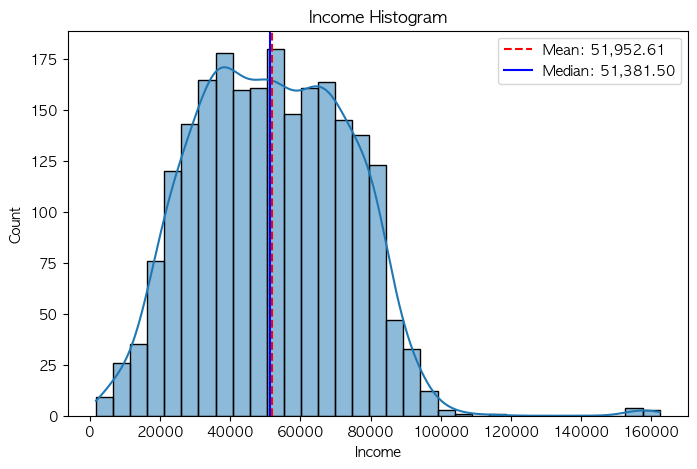

In [602]:
# TODO 1-2(a): Income 히스토그램 + KDE
plt.figure(figsize=(8,5))

sns.histplot(df["Income"], kde=True)
plt.axvline(df["Income"].mean(), color='red', linestyle='--', label=f'Mean: {df["Income"].mean():,.2f}')
plt.axvline(df["Income"].median(), color='blue', linestyle='-', label=f'Median: {df["Income"].median():,.2f}')
plt.title("Income Histogram")

plt.legend()
plt.show()

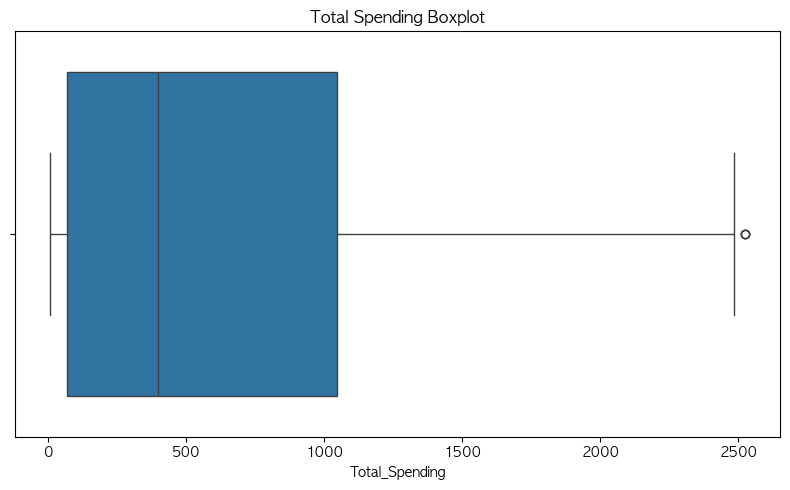

IQR 기준 이상치 개수: 3


In [603]:
# TODO 1-2(b): Total_Spending 박스플롯 + IQR 기준 이상치
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Total_Spending"])
plt.title("Total Spending Boxplot")

plt.tight_layout()
plt.show()


Q1 = df["Total_Spending"].quantile(0.25)
Q3 = df["Total_Spending"].quantile(0.75)
IQR = Q3 - Q1

iqr_lower = Q1 - 1.5 * IQR
iqr_upper = Q3 + 1.5 * IQR

iqr_outliers = df[(df["Total_Spending"] < iqr_lower) | (df["Total_Spending"] > iqr_upper)]

print("IQR 기준 이상치 개수:", len(iqr_outliers))

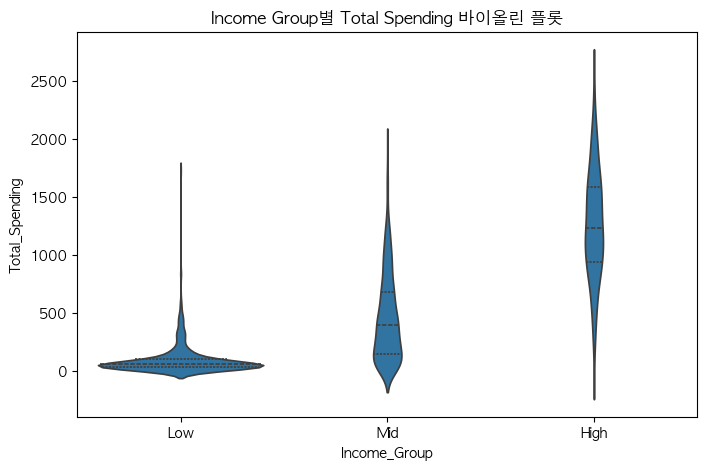

In [604]:
# TODO 1-2(c): Income_Group별 Total_Spending 바이올린 플롯
plt.figure(figsize=(8,5))

sns.violinplot(x="Income_Group", y="Total_Spending", data=df, inner='quartile')

plt.title("Income Group별 Total Spending 바이올린 플롯")
plt.show()

### 문제 1-3. 왜도와 첨도

6개 소비 카테고리(MntWines ~ MntGoldProds)의 왜도(Skewness)와 첨도(Kurtosis)를 계산하고,
2×3 히스토그램 그리드를 그려 분포 형태를 비교하세요.

**왜도 해석**
- 왜도 > 0: 오른쪽 꼬리가 긴 분포 
- 왜도 < 0: 왼쪽 꼬리가 긴 분포 
- 왜도 ≈ 0: 좌우 대칭에 가까운 분포

**첨도 해석** 
- 초과 첨도 > 0: 정규분포보다 중앙이 뾰족하고 꼬리가 두꺼운 분포 
- 초과 첨도 < 0: 정규분포보다 중앙이 평평하고 꼬리가 얇은 분포
- 초과 첨도 ≈ 0: 정규분포와 유사한 형태

In [605]:
spending_names = ['Wines', 'Fruits', 'Meat', 'Fish', 'Sweets', 'Gold']
hist_colors = [COLORS['blue'], COLORS['violet'], COLORS['teal'],
               COLORS['emerald'], COLORS['amber'], COLORS['rose']]

# TODO 1-3(a): 6개 카테고리의 왜도/첨도 계산 및 출력
category_df = df[spending_cols].agg(['skew', 'kurt']).T
category_df.columns = ['왜도', '첨도']
category_df.index = spending_names

display(category_df.round(2))

,왜도,첨도
Wines,1.18,0.60
Fruits,2.10,4.07
Meat,2.09,5.53
Fish,1.92,3.10
Sweets,2.14,4.37
Gold,1.89,3.56


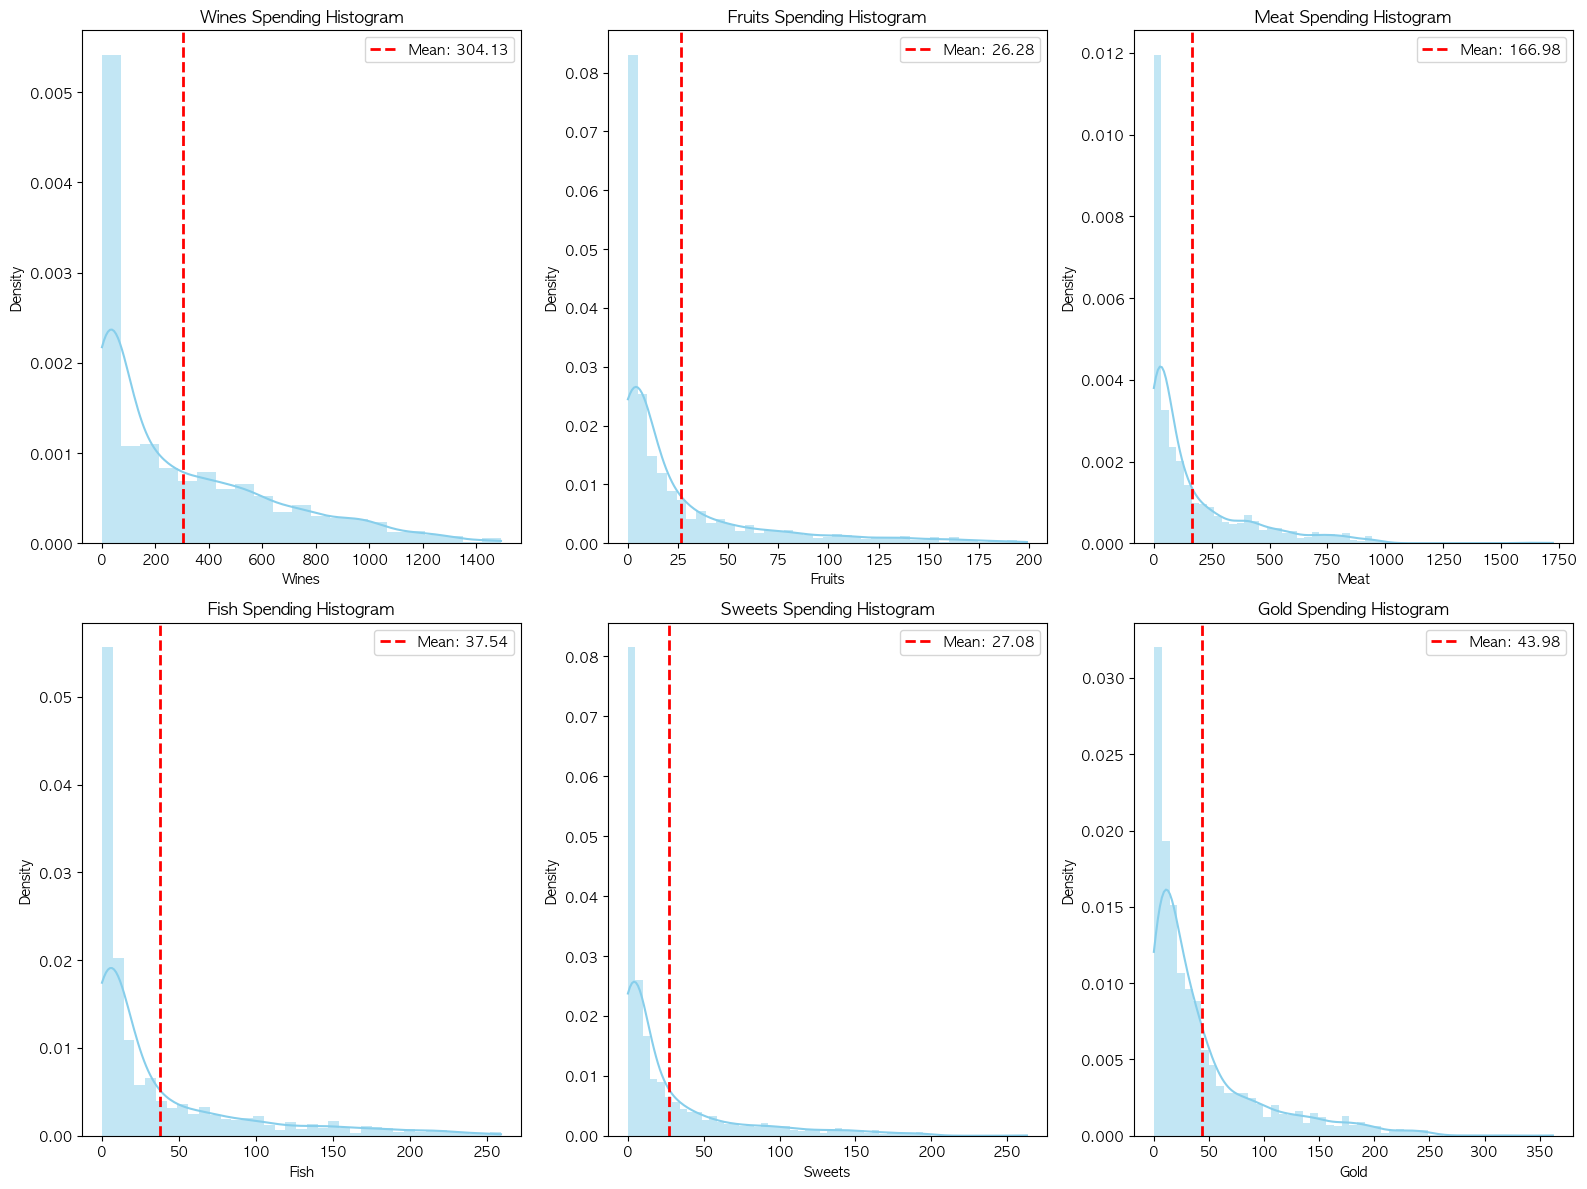

In [606]:
# TODO 1-3(b): 2×3 히스토그램 그리드 (각 카테고리 분포 + 평균선)
plt.figure(figsize=(16, 12))

for i, col in enumerate(spending_cols, 1):
    plt.subplot(2, 3, i)

    mean_val = df[col].mean()

    sns.histplot(df[col], kde=True, color='skyblue', stat="density", linewidth=0)
    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')

    plt.title(f'{spending_names[i-1]} Spending Histogram')
    plt.xlabel(spending_names[i-1])
    plt.ylabel('Density')
    plt.legend()

plt.tight_layout()
plt.show()

### 문제 1-4. 비즈니스 인사이트 정리

Part 1의 분석 결과를 바탕으로 다음을 정리하세요.

1. 고객 특성 요약 (연령, 소득, 소비 특성)
2. 핵심 발견 사항 (분포 특성, 그룹 간 차이)
3. 후속 분석에서 검증할 가설 (최소 3개)

In [607]:
# TODO 1-4: 비즈니스 인사이트 정리
print("1. 고객 특성 요약")
print("연령 : 평균, 중앙값, 절사평균이 거의 동일하고 표준편차나 변동계수가 작아 변동성이 작은 편이다. 연령은 중장년층 중심으로 비교적 균일하게 구성되어 있다고 할 수 있다.")
print("소득 : 평균>절사평균>중앙값 관계로 보아 일부의 고소득이 평균을 살짝 높이고 있다고 볼 수 있다. 중간 정도의 변동성을 가진다.")
print("소비 : 평균>절사평균>>중앙값 관계로 보아 고소비층이 평균을 많이 높이고 있다고 볼 수 있다. 변동계수로 매우 크기에 전체적으로 불균형적이며 소비 편차가 크다.")

print("\n2. 핵심 발견 사항")
print("분포 특성 : 연령 분포는 안정적인 구조이지만 소득 히스토그램과 소비 상자그림을 보면 이상치가 관측되며 특히 소비 분포는 오른쪽으로 꼬리가 긴 분포이다.")
print("그룹 간 차이 : 소득 그룹별 소비의 바이올린 그래프를 보면 소득이 클수록 소비의 중앙값이 올라가는 것을 볼 수 있다. 또한 소비 분산 역시 증가하는 것을 알 수 있다.\
      \n            따라서 소득과 소비는 양의 상관관계 가능성이 있다고 추측한다.")

print("\n3. 후속 분석에서 검증할 가설")
print("Total_Spending의 분포는 정규분포를 따르지 않을 것이다. -> 정규성 검정")
print("Income_Group이 높을수록 Total_Spending의 평균은 유의하게 증가할 것이다. -> ANOVA/선형회귀")
print("High Income_Group의 Total_Spending 분산은 다른 그룹보다 유의하게 클 것이다. -> 등분산/분산 비교")

1. 고객 특성 요약
연령 : 평균, 중앙값, 절사평균이 거의 동일하고 표준편차나 변동계수가 작아 변동성이 작은 편이다. 연령은 중장년층 중심으로 비교적 균일하게 구성되어 있다고 할 수 있다.
소득 : 평균>절사평균>중앙값 관계로 보아 일부의 고소득이 평균을 살짝 높이고 있다고 볼 수 있다. 중간 정도의 변동성을 가진다.
소비 : 평균>절사평균>>중앙값 관계로 보아 고소비층이 평균을 많이 높이고 있다고 볼 수 있다. 변동계수로 매우 크기에 전체적으로 불균형적이며 소비 편차가 크다.

2. 핵심 발견 사항
분포 특성 : 연령 분포는 안정적인 구조이지만 소득 히스토그램과 소비 상자그림을 보면 이상치가 관측되며 특히 소비 분포는 오른쪽으로 꼬리가 긴 분포이다.
그룹 간 차이 : 소득 그룹별 소비의 바이올린 그래프를 보면 소득이 클수록 소비의 중앙값이 올라가는 것을 볼 수 있다. 또한 소비 분산 역시 증가하는 것을 알 수 있다.      
            따라서 소득과 소비는 양의 상관관계 가능성이 있다고 추측한다.

3. 후속 분석에서 검증할 가설
Total_Spending의 분포는 정규분포를 따르지 않을 것이다. -> 정규성 검정
Income_Group이 높을수록 Total_Spending의 평균은 유의하게 증가할 것이다. -> ANOVA/선형회귀
High Income_Group의 Total_Spending 분산은 다른 그룹보다 유의하게 클 것이다. -> 등분산/분산 비교


---
## Part 2: 확률분포 모델링 — "고객 행동은 어떤 패턴을 따르는가?"

실제 고객 데이터에 이론적 확률분포를 적합하여 고객 행동을 모델링합니다.

### 문제 2-1. 이항분포 — 캠페인 수락 모델링

`Response` 열에서 수락률 p를 계산하고, 이를 이항분포 B(n, p)에 적용합니다.

- **(a)** 10명 중 정확히 2명이 수락할 확률
  - B(n=10, p) 에서 P(X = 2) 계산

- **(b)** 10명 중 3명 이상이 수락할 확률
  - B(n=10, p) 에서 P(X ≥ 3) 계산

- **(c)** 이항분포 PMF 시각화
  - B(n=10, p) 의 모든 경우(X = 0, 1, ..., 10)에 대한
    이론 확률을 막대그래프로 그립니다.

- **(d)** n=100 으로 확장 — 세 가지 질문
  - **기대 수락자 수**: E(X) 계산
  - **15명 이상 수락 확률**: P(X ≥ 15) 계산
  - **90% 보장 최소 수락 수**: P(X ≤ k) ≥ 0.90 을 만족하는 최솟값 k 탐색

In [608]:
# TODO 2-1(a),(b): 수락률(p) 계산 + P(X=2), P(X≥3) 계산 및 출력
n_trial = 10
response_rate = sum(df["Response"]) / len(df["Response"])

binom_dist = stats.binom(n=n_trial, p=response_rate)

print(f"(a) P(X=2) = {binom_dist.pmf(2):.3f}")
print(f"(b) P(X≥3) = {1-binom_dist.cdf(2):.3f}")

(a) P(X=2) = 0.275
(b) P(X≥3) = 0.178


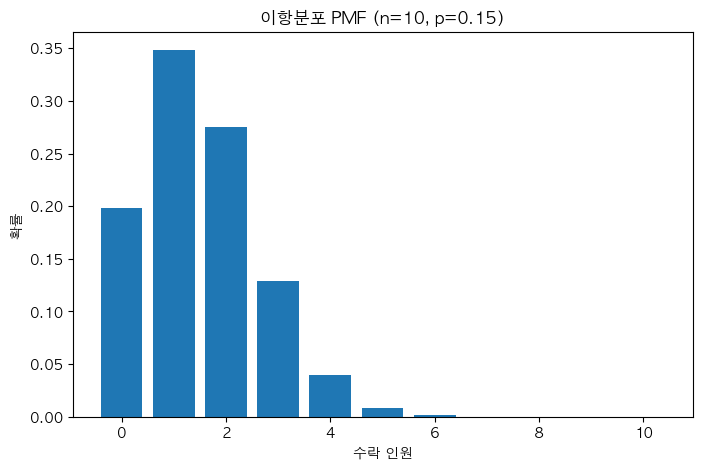

In [609]:
# TODO 2-1(c): 이항분포 PMF 시각화
n = n_trial
p = response_rate
k = np.arange(0, n+1)
pmf = stats.binom.pmf(k, n, p)

plt.figure(figsize=(8,5))
plt.bar(k, pmf)

plt.xlabel("수락 인원")
plt.ylabel("확률")
plt.title(f"이항분포 PMF (n={n}, p={p:.2f})")

plt.show()

In [610]:
# TODO 2-1(d): 100명 발송 시 기대 수락자, P(X≥15), 90% 보장 최소 수락 수
n_campaign = 100
binom_dist2 = stats.binom(n=n_campaign, p=response_rate)

print(f"E(X) = {binom_dist2.mean():.3f}")
print(f"P(X≥15) = {binom_dist2.sf(14):.3f}")
print(f"P(X≤k) ≥ 0.90 을 만족하는 최솟값 k : {int(np.ceil(binom_dist2.ppf(0.9)))}명")

E(X) = 14.937
P(X≥15) = 0.536
P(X≤k) ≥ 0.90 을 만족하는 최솟값 k : 20명


### 문제 2-2. 포아송 분포 — 웹사이트 방문 모델링

`NumWebVisitsMonth`(월간 웹 방문 수)에 포아송 분포를 적합합니다.

- **(a)** λ 추정 및 적합 평가
  - 표본 평균으로 λ를 추정하고,
    표본 평균 ≈ 표본 분산인지 확인하여 포아송 분포 적합 여부를 평가합니다.

- **(b)** 실측 vs 이론 PMF 시각화
  - 각 방문 횟수(0회, 1회, 2회, ...)별 실제 비율(실측 PMF)과
    포아송 분포의 이론 확률(이론 PMF)을 막대그래프로 겹쳐 그려 비교합니다.

- **(c)** 포아송 분포 활용 — 두 가지 실무 시나리오
  - **과다 방문 고객 비율**: P(X ≥ 10) 계산
    → 추정된 포아송 분포에서 월 10회 이상 방문할 확률이 몇 %인지 구합니다.
  - **서버 용량 계획**: 상위 5% 기준값 k 계산, 즉 P(X ≤ k) = 0.95 를 만족하는 k 탐색
    → 전체 고객의 95%를 커버할 수 있는 최대 방문 횟수를 구하고,
       이를 서버가 처리해야 할 기준 용량으로 활용합니다.

In [611]:
web_visits = df['NumWebVisitsMonth']

# TODO 2-2(a): 람다 추정 및 포아송 적합 평가 (월간 웹 방문수 평균≈분산 값이 비슷한지 확인)
print(f"λ(표본평균) = {web_visits.mean():.4f}")
print(f"표본분산    = {web_visits.var():.4f}")
print(f"포아송분포 Despersion (분산/평균) = {web_visits.var()/web_visits.mean():.3f}")
print("=> 분산 평균 비율이 1에 가까우므로 포아송 분포가 적합하다고 할 수 있다.")

λ(표본평균) = 5.3189
표본분산    = 5.8898
포아송분포 Despersion (분산/평균) = 1.107
=> 분산 평균 비율이 1에 가까우므로 포아송 분포가 적합하다고 할 수 있다.


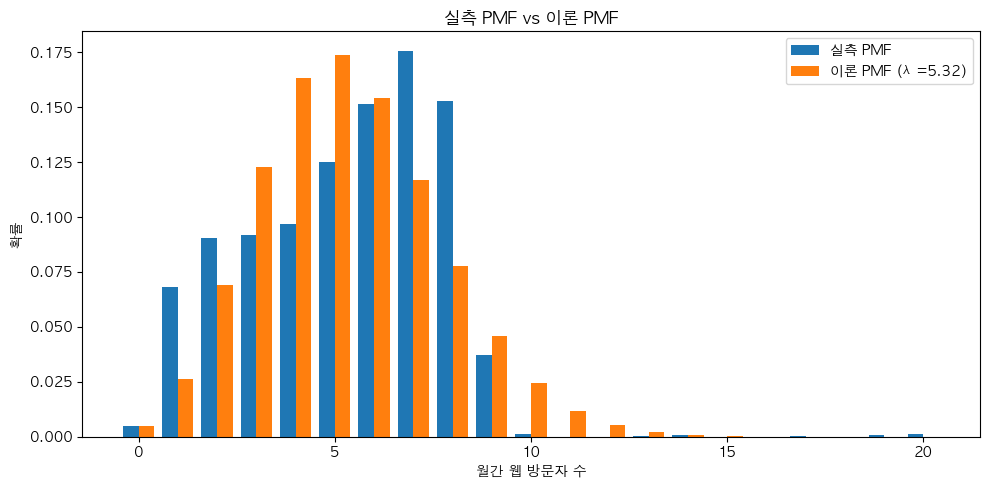

In [612]:
# TODO 2-2(b): 월간 웹 방문수 막대그래프 vs 이론 PMF 비교 시각화 (두 그래프를 겹쳐서 그리기)
k = np.arange(0, web_visits.max() + 1)
lam = web_visits.mean()

emp_pmf = web_visits.value_counts(normalize=True).reindex(k, fill_value=0).values
theo_pmf = stats.poisson.pmf(k, mu=lam)

plt.figure(figsize=(10,5))
plt.bar(k - 0.2, emp_pmf, width=0.4, label="실측 PMF")
plt.bar(k + 0.2, theo_pmf, width=0.4, label=f"이론 PMF (λ={lam:.2f})")

plt.xlabel("월간 웹 방문자 수")
plt.ylabel("확률")
plt.title("실측 PMF vs 이론 PMF")
plt.legend()
plt.tight_layout()
plt.show()

In [613]:
# TODO 2-2(c):
# - 과다 방문 고객: 포아송 분포로 P(X ≥ 10) 계산 (월 10회 이상 방문 확률)
# - 서버 용량 계획: P(X ≤ k) ≥ 0.95 를 만족하는 최솟값 k 탐색 (상위 5% 기준)
heavy_threshold = 10

cum_prob = stats.poisson.sf(heavy_threshold-1, mu=lam)
print(f"P(X≥10) = {cum_prob:.3f} ({cum_prob * 100:.1f}%)")
print(f"P(X≤k) ≥ 0.95 를 만족하는 최솟값 k : {int(np.ceil(stats.poisson.ppf(0.95, mu=lam)))}명")

P(X≥10) = 0.045 (4.5%)
P(X≤k) ≥ 0.95 를 만족하는 최솟값 k : 9명


### 문제 2-3. 정규분포 — 소득 모델링

`Income`에 정규분포를 적합합니다.
Part 1에서 Income의 왜도가 작고 평균≈중앙값임을 확인했습니다. 정규분포가 잘 맞을까요?

- **(a)** μ, σ 추정 후 CDF로 P(Income < 30000), P(Income > 80000) 계산,
 PPF로 상위 10% 소득 기준값 계산 — **이론 확률과 실측 비율을 비교**하세요
- **(b)** 히스토그램 + 정규 분포 PDF와 겹쳐 그리기
- **(c)** 정규분포 활용 — 두 가지 질문
  - **VIP 기준선**: 상위 5% 소득 기준값
    → "이 금액 이상이면 VIP 고객으로 분류"
  - **할인 대상 기준선**: 하위 10% 소득 기준값
    → "이 금액 이하이면 할인 대상 고객으로 분류"


In [614]:
# TODO 2-3(a): μ, σ 추정 → CDF로 P(Income<30000), P(Income>80000) 계산
#               PPF로 상위 10% 소득 기준값 계산 → 이론 확률과 실측 비율 비교
Income = df["Income"]
mu = Income.mean()
sigma = Income.std(ddof=1)

print(f"μ (평균) = {mu:,.2f}")
print(f"σ (표준편차) = {sigma:,.2f}")

norm_dist = stats.norm(loc=mu, scale=sigma)

p_less_30000 = norm_dist.cdf(30000)
p_greater_80000 = 1 - norm_dist.cdf(80000)
top_10_income = norm_dist.ppf(0.9)

emp_less_30000 = (Income < 30000).mean()
emp_greater_80000 = (Income > 80000).mean()
emp_top_10_income = Income.quantile(0.9)

income_table = pd.DataFrame({
    "이론": [
        f"{p_less_30000:.3f}",
        f"{p_greater_80000:.3f}",
        f"{top_10_income:,.2f}"
    ],
    "실측": [
        f"{emp_less_30000:.3f}",
        f"{emp_greater_80000:.3f}",
        f"{emp_top_10_income:,.2f}"
    ]
}, index=[
    "P(Income < 30000)",
    "P(Income > 80000)",
    "상위 10% 소득 기준값"
])

display(income_table)

print("=> 이론값과 실측값이 비슷하기에 Income의 분포는 정규분포에 가깝다고 할 수 있다.")

μ (평균) = 51,952.61
σ (표준편차) = 21,411.47


,이론,실측
P(Income < 30000),0.153,0.165
P(Income > 80000),0.095,0.096
상위 10% 소득 기준값,"79,392.51","79,747.50"


=> 이론값과 실측값이 비슷하기에 Income의 분포는 정규분포에 가깝다고 할 수 있다.


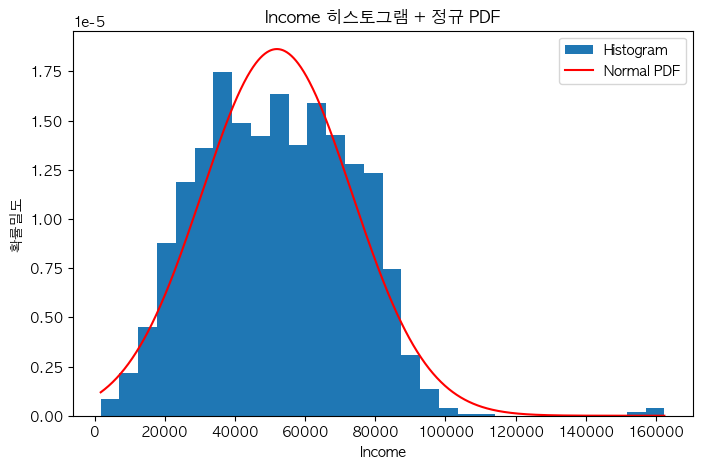

In [615]:
# TODO 2-3(b): 히스토그램 + 정규 PDF 겹쳐 그리기
plt.figure(figsize=(8,5))
plt.hist(Income, bins=30, density=True, label="Histogram")

x = np.linspace(Income.min(), Income.max(), 1000)
pdf = norm_dist.pdf(x)
plt.plot(x, pdf, 'r-', label="Normal PDF")

plt.title("Income 히스토그램 + 정규 PDF")
plt.xlabel("Income")
plt.ylabel("확률밀도")
plt.legend()
plt.show()

In [616]:
# TODO 2-3(c): 실무 시나리오 — VIP(상위 5%) 기준선 + 할인 대상(하위 10%) 기준선
vip_cutoff = norm_dist.ppf(0.95)
print(f"VIP 기준선 (상위 5%): {vip_cutoff:,.2f}")

discount_cutoff = norm_dist.ppf(0.10)
print(f"할인 대상 기준선 (하위 10%): {discount_cutoff:,.2f}")

VIP 기준선 (상위 5%): 87,171.34
할인 대상 기준선 (하위 10%): 24,512.72


---
## Part 3: 추정과 가설검정 — "고소득 고객과 저소득 고객의 소비는 다른가?"

신뢰구간과 가설검정을 통해 고객 그룹 간 차이를 통계적으로 검증합니다.

### 문제 3-1. 신뢰구간 추정

- **(a)** Total_Spending 평균의 90%, 95%, 99% 신뢰구간을 계산하세요.
- **(b)** Income_Group별 95% CI를 계산하고 오차막대 그래프로 비교하세요.

CI = [x̄ - t × SE, x̄ + t × SE] (SE = s / √n)

In [617]:
# TODO 3-1(a): Total_Spending 평균의 신뢰구간 (90%, 95%, 99%)
# CI = x̄ ± t(α/2, n-1) × SE
total_spending = df["Total_Spending"]

n = len(total_spending)
xbar = np.mean(total_spending)
s = np.std(total_spending, ddof=1)
se = s / np.sqrt(n)

for confidence in [0.90, 0.95, 0.99]:
    alpha = 1 - confidence 
    t_crit = stats.t.ppf(1-alpha/2, df=n-1)
    margin = t_crit * se
    ci_low = xbar - margin
    ci_high = xbar + margin
    print(f"신뢰수준 {confidence*100:.0f}% CI: [{ci_low:.2f}, {ci_high:.2f}]")

신뢰수준 90% CI: [585.04, 626.93]
신뢰수준 95% CI: [581.03, 630.95]
신뢰수준 99% CI: [573.17, 638.80]


              CI_lower  CI_upper
Income_Group                    
Low           27825.72  29042.42
Mid           51082.35  52009.52
High          75075.42  76743.39


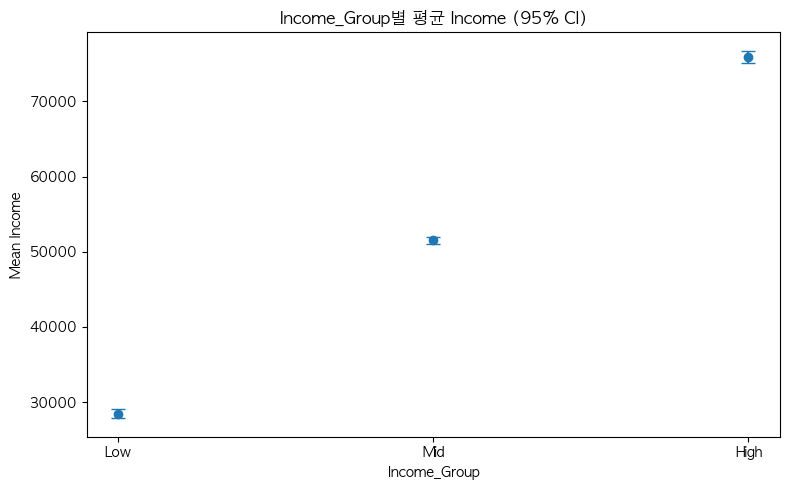

In [618]:
# TODO 3-1(b): Income_Group별 95% CI 계산 + 오차막대 그래프
Income_grouped = df.groupby("Income_Group")["Income"]

def ci_95(x):
    mean = x.mean()
    se = x.std(ddof=1) / np.sqrt(len(x))
    t_crit = stats.t.ppf(0.975, df=len(x)-1)
    return pd.Series({
        "CI_lower" : mean - t_crit * se,
        "CI_upper" : mean + t_crit * se
    })

ci_table = Income_grouped.apply(ci_95).unstack()
print(ci_table.round(2))

means = Income_grouped.mean()
yerr = means - ci_table["CI_lower"]   # = t*se

plt.figure(figsize=(8,5))

plt.errorbar(means.index, means, yerr=yerr, fmt='o', capsize=5)

plt.title("Income_Group별 평균 Income (95% CI)")
plt.xlabel("Income_Group")
plt.ylabel("Mean Income")
plt.tight_layout()
plt.show()

### 문제 3-2. 독립표본 t-검정 (Welch's t-test)

**가설**: 자녀가 없는 고객의 총 소비가 자녀가 있는 고객과 다른가?

- H₀: μ_무자녀 = μ_유자녀
- H₁: μ_무자녀 ≠ μ_유자녀

Cohen's d 해석 기준: |d| < 0.5 작은, 0.5~0.8 중간, > 0.8 큰 효과

In [619]:
no_child = df[~df['Has_Children']]['Total_Spending']
yes_child = df[df['Has_Children']]['Total_Spending']

# TODO 3-2: Welch's t-검정 수행 + Cohen's d 계산 + 결과 출력
print(f"H0: μ_무자녀 = μ_유자녀 (자녀의 유무에 따라 소비에 차이가 없다)")
print(f"H1: μ_무자녀 ≠ μ_유자녀 (자녀의 유무에 따라 소비에 차이가 있다)")

t_stat, p_value = stats.ttest_ind(no_child, yes_child, equal_var=False)

mean_no, mean_yes = no_child.mean(), yes_child.mean()
var_no, var_yes = no_child.var(ddof=1), yes_child.var(ddof=1)
n_no, n_yes = len(no_child), len(yes_child)
s_pooled = np.sqrt(((n_no-1) * var_no + (n_yes-1) * var_yes) / (n_no + n_yes - 2))

cohen_d = (mean_no - mean_yes) / s_pooled

print("\n== Welch's t-test 결과 ==")
print(f"t = {t_stat:.3f}, p = {p_value:.4f}")
print(f"Cohen's d = {cohen_d:.3f}")
print("\n=> p-값이 매우 작으므로 귀무가설을 기각한다. \
      \n   따라서, 자녀 유무에 따른 Total_Spending 평균에는 차이가 있다고 할 수 있다.\
      \n   또한 Cohen's d = 1.36으로, 효과 크기 역시 매우 큰 수준으로 나타났다.")

H0: μ_무자녀 = μ_유자녀 (자녀의 유무에 따라 소비에 차이가 없다)
H1: μ_무자녀 ≠ μ_유자녀 (자녀의 유무에 따라 소비에 차이가 있다)

== Welch's t-test 결과 ==
t = 24.989, p = 0.0000
Cohen's d = 1.360

=> p-값이 매우 작으므로 귀무가설을 기각한다.       
   따라서, 자녀 유무에 따른 Total_Spending 평균에는 차이가 있다고 할 수 있다.      
   또한 Cohen's d = 1.36으로, 효과 크기 역시 매우 큰 수준으로 나타났다.


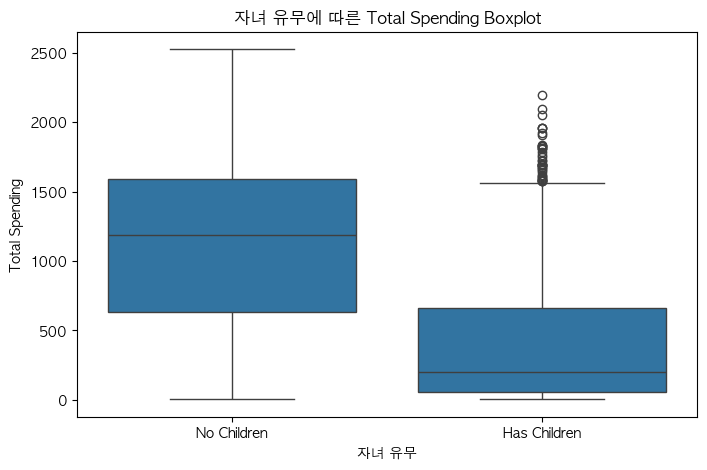

In [620]:
# TODO 3-2(c): 박스플롯 비교 시각화
plt.figure(figsize=(8,5))

sns.boxplot(x="Has_Children", y="Total_Spending", data=df)

plt.xticks([0,1], ["No Children", "Has Children"])
plt.title("자녀 유무에 따른 Total Spending Boxplot")
plt.xlabel("자녀 유무")
plt.ylabel("Total Spending")

plt.show()


### 문제 3-3. 대응표본 t-검정

같은 고객의 **와인 소비**(`MntWines`)와 **육류 소비**(`MntMeatProducts`)를 비교합니다.

- H₀: μ_Wine = μ_Meat (차이 = 0)
- H₁: μ_Wine ≠ μ_Meat

In [621]:
wines = df['MntWines']
meat = df['MntMeatProducts']

# TODO 3-3: 차이 계산 + 대응표본 t-검정 + Cohen's d + 결과 출력
print(f"H0: μ_Wine = μ_Meat (차이가 없다)")
print(f"H1: μ_Wine ≠ μ_Meat (차이가 있다)")

t_stat2, p_value2 = stats.ttest_rel(meat, wines)

diff = meat - wines
cohen_d2 = diff.mean() / diff.std(ddof=1)

print("\n== 대응표본 t-test 결과 ==")
print(f"t = {t_stat2:.3f}, p = {p_value2:.4f}")
print(f"Cohen's d = {cohen_d2:.3f}")
print("\n=> p-값이 매우 작으므로 귀무가설을 기각한다. \
      \n   따라서, 와인 소비와 육류 소비에 차이가 있다고 할 수 있다.\
      \n   또한 t 통계량이 음수인 것을 보아 와인의 소비가 육류의 소비보다 크다는 것을 알 수 있다.\
      \n   하지만 |Cohen's d|값이 0.5보다 작으므로, 효과 크기는 작은 것으로 나타났다.")

H0: μ_Wine = μ_Meat (차이가 없다)
H1: μ_Wine ≠ μ_Meat (차이가 있다)

== 대응표본 t-test 결과 ==
t = -23.093, p = 0.0000
Cohen's d = -0.488

=> p-값이 매우 작으므로 귀무가설을 기각한다.       
   따라서, 와인 소비와 육류 소비에 차이가 있다고 할 수 있다.      
   또한 t 통계량이 음수인 것을 보아 와인의 소비가 육류의 소비보다 크다는 것을 알 수 있다.      
   하지만 |Cohen's d|값이 0.5보다 작으므로, 효과 크기는 작은 것으로 나타났다.


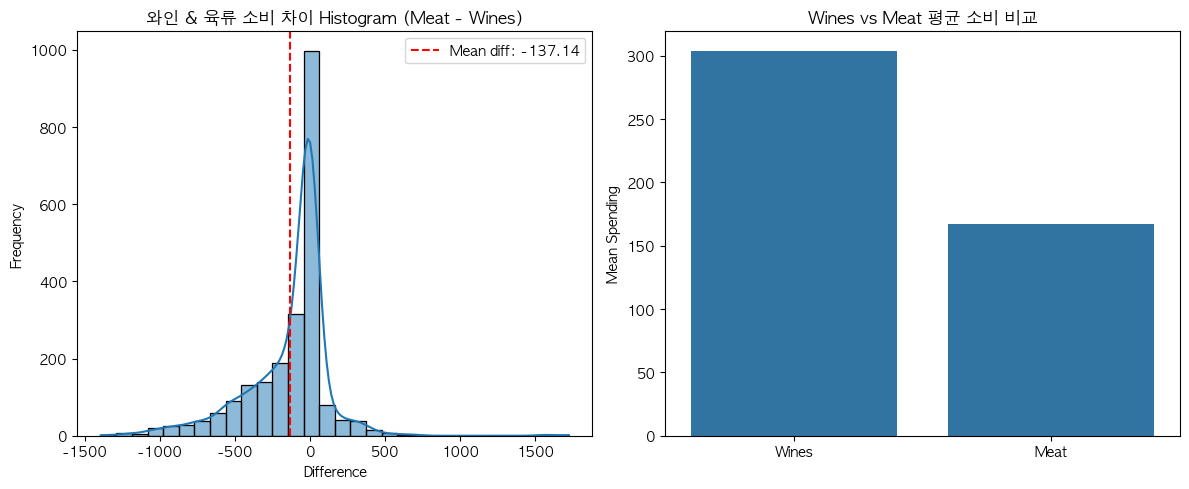

In [622]:
# TODO 3-3(b): (1) 대응 차이 히스토그램 (2) 카테고리별 평균 비교 막대그래프
means = [wines.mean(), meat.mean()]
labels = ["Wines", "Meat"]

fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(diff, bins=30, kde=True, ax=axes[0])
axes[0].axvline(diff.mean(), color='red', linestyle='--',
                label=f"Mean diff: {diff.mean():.2f}")
axes[0].set_title("와인 & 육류 소비 차이 Histogram (Meat - Wines)")
axes[0].set_xlabel("Difference")
axes[0].set_ylabel("Frequency")
axes[0].legend()

sns.barplot(x=labels, y=means, ax=axes[1])
axes[1].set_title("Wines vs Meat 평균 소비 비교")
axes[1].set_ylabel("Mean Spending")

plt.tight_layout()
plt.show()

### 문제 3-4. 검정력 분석

- **(a)** 문제 3-2의 효과 크기와 표본 크기를 사용하여 검정력(Power)을 계산하세요.
- **(b)** 작은 효과(d=0.2)를 탐지하기 위해 필요한 그룹당 표본 크기를 구하세요.

In [623]:
power_analysis = TTestIndPower()

# TODO 3-4(a): 문제 3-2 기준 검정력 계산
n1 = n_no
n2 = n_yes
ratio = n_yes/n_no
d = abs(cohen_d)

power = power_analysis.power(
    effect_size=d,
    nobs1=n1,
    ratio=ratio,
    alpha=0.05,
    alternative='two-sided'
)
print(f"(a) 검정력 : {power}")
print("    => 효과크기와 표본크기가 충분히 크기에 검정력이 1에 매우 근접하여 이런 결과가 발생한 것으로 판단됨.")

dof = n1 + n2 - 2
t_crit = stats.t.ppf(1-0.05/2, df=dof)
delta = d * np.sqrt((n1 * n2) / (n1 + n2))
power_manual = 1 - stats.nct.cdf(t_crit, dof, delta) + stats.nct.cdf(-t_crit, dof, delta)
print(f"    수동으로 계산한 검정력: {power_manual}")


# TODO 3-4(b): 작은 효과(d=0.2) 탐지에 필요한 표본 크기 산정
n_req = power_analysis.solve_power(
    effect_size=0.2,
    nobs1=None,
    ratio=1,
    alpha=0.05,
    power=0.8,
    alternative='two-sided'
)
print(f"(b) 그룹당 필요한 표본 수 : {int(np.ceil(n_req))}명")
print(f"    총 필요한 표본 수 : {int(np.ceil(n_req)*2)}명")

(a) 검정력 : nan
    => 효과크기와 표본크기가 충분히 크기에 검정력이 1에 매우 근접하여 이런 결과가 발생한 것으로 판단됨.
    수동으로 계산한 검정력: 1.0
(b) 그룹당 필요한 표본 수 : 394명
    총 필요한 표본 수 : 788명


---
## Part 4: 고급 검정 — "교육, 결혼, 캠페인 반응의 관계는?"

정규성 검정을 바탕으로 적절한 검정 방법을 선택하고,
범주형 변수 간 관계를 분석합니다.

### 문제 4-1. 정규성 + 등분산 검정

Education_Group별 Total_Spending의 정규성을 Shapiro-Wilk 검정과 Q-Q Plot으로 확인하세요.
정규성이 기각되더라도, 표본이 충분히 크면(n ≥ 30) 중심극한정리(CLT)에 의해
ANOVA가 여전히 강건(robust)합니다. 각 그룹의 표본 크기도 함께 확인하세요.

⚠️ **등분산성 위반은 CLT와 무관합니다** — 표본이 아무리 커도 해결되지 않습니다.
Levene 검정으로 등분산 가정을 확인하고, 위반 시 Welch's ANOVA를 사용합니다.

In [624]:
edu_groups = ['Undergraduate', 'Graduate', 'Postgraduate']

# TODO 4-1(a): Shapiro-Wilk 검정 (각 그룹별)
print("(a) 그룹별 Shapiro-Wilk 검정")

for group in edu_groups:
    data = df[df["Education_Group"] == group]["Total_Spending"]
    
    stat_sw, p_sw = stats.shapiro(data)
    
    result = "정규성 유지" if (p_sw is not None and p_sw > 0.05) else "정규성 위반"
    if p_sw is not None and p_sw <= 0.05:
        normality_ok = False
    stat_viz = stat_sw if stat_sw is not None else 0
    p_viz = p_sw if p_sw is not None else 0
    print(f"    {group}: W={stat_viz:.4f}, p={p_viz:.4f} ({result})")

if normality_ok:
    print("\n    => 모든 집단이 정규분포를 따르므로 등분산 검정으로 진행합니다")
else:
    print("\n    => 정규성 위반 집단이 있으므로 Kruskal-Wallis 검정을 고려합니다")


# TODO 4-1(b): Levene 등분산 검정 → use_welch = True/False 설정
use_welch = None

group_data = [
    df[df["Education_Group"] == group]["Total_Spending"].dropna()
    for group in edu_groups
]

stat, p = stats.levene(*group_data)

print("\n(b) Levene 등분산 검정")
print(f"    Levene 통계량 = {stat:.4f}, p-value = {p:.4f}")

if p < 0.05:
    use_welch = True
    print("    등분산 가정 위반 : Welch's ANOVA 사용")
else:
    use_welch = False
    print("    등분산 가정 충족 : One-way ANOVA 사용")

(a) 그룹별 Shapiro-Wilk 검정
    Undergraduate: W=0.7605, p=0.0000 (정규성 위반)
    Graduate: W=0.8743, p=0.0000 (정규성 위반)
    Postgraduate: W=0.8765, p=0.0000 (정규성 위반)

    => 정규성 위반 집단이 있으므로 Kruskal-Wallis 검정을 고려합니다

(b) Levene 등분산 검정
    Levene 통계량 = 13.2893, p-value = 0.0000
    등분산 가정 위반 : Welch's ANOVA 사용


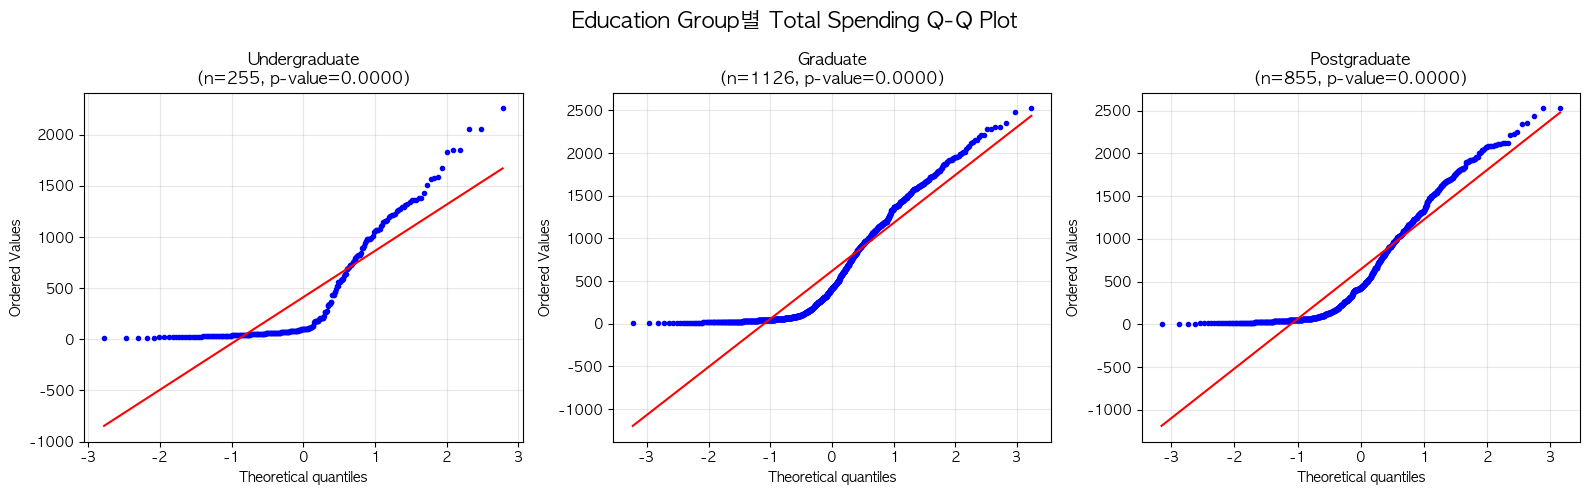

In [625]:
# TODO 4-1(b): Q-Q Plot (1×3 서브플롯)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Education Group별 Total Spending Q-Q Plot', fontsize=16)

for i, group in enumerate(edu_groups):
    data = df[df['Education_Group'] == group]['Total_Spending']
    
    stats.probplot(data, dist="norm", plot=axes[i])
    sw_p = stats.shapiro(data).pvalue

    axes[i].set_title(f'{group}\n(n={len(data)}, p-value={sw_p:.4f})')
    axes[i].get_lines()[0].set_markersize(3)
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 문제 4-2. ANOVA + 사후검정

문제 4-1의 정규성/등분산 검정 결과에 따라 적절한 검정을 수행합니다.

- 등분산 만족 → One-way ANOVA + **Tukey HSD** + Cohen's d
- 등분산 위반 → Welch's ANOVA + **Games-Howell** (`pg.pairwise_gameshowell()`) + Hedges' g
- 참고로 비모수 검정(Kruskal-Wallis)도 병행하여 결과의 일관성을 확인하세요.
- 효과 크기: η² + ω² (기준: 0.01 작은, 0.06 중간, 0.14 큰)
- 쌍별 효과 크기: Cohen's d / Hedges' g (기준: 0.2 미만 매우 작은, 0.2~0.5 작은, 0.5~0.8 중간, 0.8 이상 큰)

In [626]:
group_data = {g: df[df['Education_Group'] == g]['Total_Spending'].values for g in edu_groups}

# TODO 4-2(a): use_welch에 따라 ANOVA / Welch's ANOVA 수행 (Kruskal-Wallis도 병행)
if use_welch:
    print("== Welch's ANOVA 검정 ==")
    welch = pg.welch_anova(data=df, dv='Total_Spending', between='Education_Group')
    display(welch)
    if welch['p-unc'].values[0] < 0.05:
        print("H₀ 기각: 그룹별 소비에 유의한 차이가 있다.")
    else:
        print("H₀ 기각 못함: 그룹별 소비에 유의한 차이가 있다고 할 수 없다.")
else:
    print("== One-way ANOVA 검정 ==")
    anova = pg.anova(data=df, dv='Total_Spending', between='Education_Group')
    display(anova)
    if anova['p-unc'].values[0] < 0.05:
        print("H₀ 기각: 그룹별 소비에 유의한 차이가 있다.")
    else:
        print("H₀ 기각 못함: 그룹별 소비에 유의한 차이가 있다고 할 수 없다.")        

print("\n== Kruskal-Wallis 검정 ==")
kruskal = pg.kruskal(data=df, dv='Total_Spending', between='Education_Group')
display(kruskal)
if kruskal['p-unc'].values[0] < 0.05:
    print("H₀ 기각: 그룹별 소비에 유의한 차이가 있다.")
else:
    print("H₀ 기각 못함: 그룹별 소비에 유의한 차이가 있다고 할 수 없다.")  


# TODO 4-2(b): η² + ω² 계산 — ω² = (SS_between - (k-1)*MS_within) / (SS_total + MS_within)
if use_welch:
    eta = welch['np2'].values[0]
else:
    eta = anova['np2'].values[0]

size_eta = '작은' if eta < 0.06 else '중간' if eta < 0.14 else '큰'
print(f"\n(b) 효과크기 : η² = {eta:.4f} ({size_eta} 효과)")

== Welch's ANOVA 검정 ==


,Source,ddof1,ddof2,F,p-unc,np2
0,Education_Group,2,751.708152,19.817377,4.098696e-09,0.0137


H₀ 기각: 그룹별 소비에 유의한 차이가 있다.

== Kruskal-Wallis 검정 ==


,Source,ddof1,H,p-unc
Kruskal,Education_Group,2,36.613323,1.120774e-08


H₀ 기각: 그룹별 소비에 유의한 차이가 있다.

(b) 효과크기 : η² = 0.0137 (작은 효과)


In [627]:
# TODO 4-2(c): 사후검정 수행 + 해석 + 쌍별 효과크기
# 등분산 만족 → Tukey HSD + Cohen's d
# 등분산 위반 → Games-Howell (pg.pairwise_gameshowell) + Hedges' g
from itertools import combinations

if use_welch:
    print("== Games-Howell 사후검정 ==")
    gh = pg.pairwise_gameshowell(data=df, dv='Total_Spending', between='Education_Group')
    display(gh)
    
    print("\n== 쌍별 효과 크기 (Hedges' g) ==")
    for (g1, d1), (g2, d2) in combinations(group_data.items(), 2):
        g = pg.compute_effsize(d1, d2, eftype='hedges')
        size_g = '매우 작은' if abs(g) < 0.2 else '작은' if abs(g) < 0.5 else '중간' if abs(g) < 0.8 else '큰'
        print(f"  {g1} vs {g2}: Hedges' g = {g:.3f} ({size_g} 효과)")

else:
    print("== Tukey HSD 사후검정 ==")
    tukey = pairwise_tukeyhsd(endog=df['Total_Spending'], groups=df['Education_Group'], alpha=0.05)
    print(tukey)
    
    print("\n== 쌍별 효과 크기 (Cohen's d) ==")
    for (g1, d1), (g2, d2) in combinations(group_data.items(), 2):
        d = pg.compute_effsize(d1, d2, eftype='cohen')
        size_d = '매우 작은' if abs(d) < 0.2 else '작은' if abs(d) < 0.5 else '중간' if abs(d) < 0.8 else '큰'
        print(f"  {g1} vs {g2}: Cohen's d = {d:.3f} ({size_d} 효과)")

== Games-Howell 사후검정 ==


,A,B,mean(A),mean(B),diff,se,T,df,pval,hedges
0,Graduate,Postgraduate,620.394316,644.791813,-24.397497,27.691976,-0.881031,1808.339544,6.523632e-01,-0.040121
1,Graduate,Undergraduate,620.394316,412.254902,208.139414,36.852786,5.647861,425.032927,8.920634e-08,0.355688
2,Postgraduate,Undergraduate,644.791813,412.254902,232.536911,38.554847,6.031328,492.811108,9.577127e-09,0.389636



== 쌍별 효과 크기 (Hedges' g) ==
  Undergraduate vs Graduate: Hedges' g = -0.356 (작은 효과)
  Undergraduate vs Postgraduate: Hedges' g = -0.390 (작은 효과)
  Graduate vs Postgraduate: Hedges' g = -0.040 (매우 작은 효과)


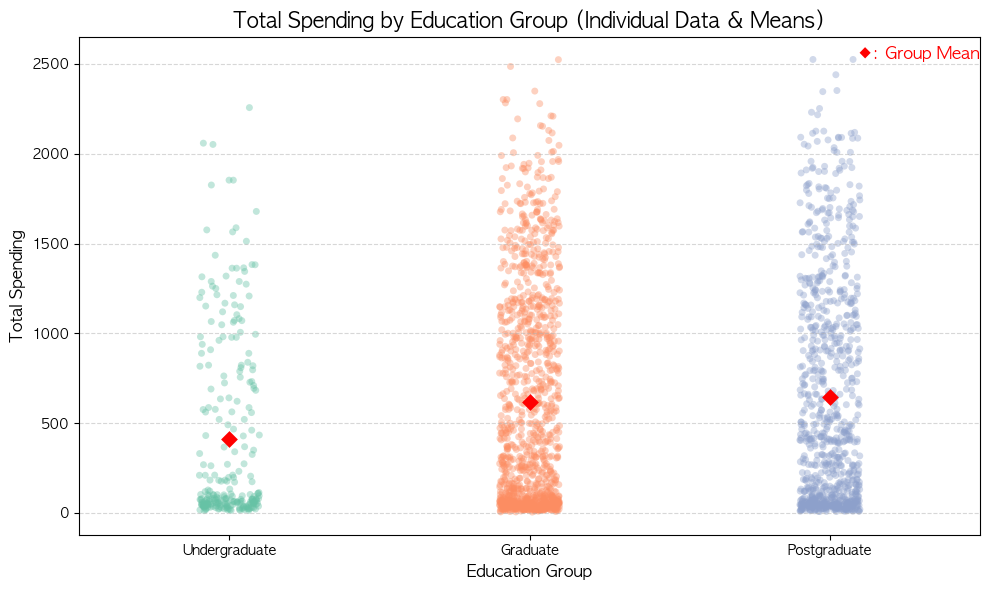

In [628]:
# TODO 4-2(d): 시각화 — 그룹별 개별 데이터 산점도 + 평균 다이아몬드
plt.figure(figsize=(10, 6))

sns.stripplot(x='Education_Group', y='Total_Spending', data=df, 
              order=edu_groups, palette='Set2', jitter=True, alpha=0.4, zorder=1)

sns.pointplot(x='Education_Group', y='Total_Spending', data=df, 
              order=edu_groups, join=False, markers='D', color='red', 
              scale=1.2, errorbar=None, zorder=3)

plt.title('Total Spending by Education Group (Individual Data & Means)', fontsize=15)
plt.xlabel('Education Group', fontsize=12)
plt.ylabel('Total Spending', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.text(2.5, df['Total_Spending'].max(), '◆: Group Mean', color='red', 
         fontsize=12, fontweight='bold', ha='right')

plt.tight_layout()
plt.show()

### 문제 4-3. 카이제곱 독립성 검정

**가설**: 결혼 상태(Marital_Group)와 캠페인 반응(Campaign_Response)은 독립인가?

- H₀: Marital_Group과 Campaign_Response는 독립이다.
- H₁: 두 변수는 독립이 아니다.

- 효과크기: φ (phi) = √(χ² / n) (기준: 0.1 작은, 0.3 중간, 0.5 큰)
- 오즈비(Odds Ratio): OR = (a×d) / (b×c), 95% CI = exp(ln(OR) ± 1.96 × SE)

> ⚠️ Cochran 규칙: 기대빈도 < 5인 셀이 전체의 20% 초과 시 Fisher 정확검정 필요

In [629]:
crosstab_no_margin = pd.crosstab(df['Marital_Group'], df['Campaign_Response'])

# TODO 4-3(a): 카이제곱 검정 수행 + Cochran 규칙 확인
print("== 카이제곱 검정 ==")
chi2_ind, p_ind, dof_ind, expected_ind = stats.chi2_contingency(crosstab_no_margin)

print(f"카이제곱 통계량: {chi2_ind:.4f}")
print(f"p-value: {p_ind:.4f}")
print(f"자유도: {dof_ind}")

expected_df = pd.DataFrame(expected_ind, index=crosstab_no_margin.index, columns=crosstab_no_margin.columns)
display(expected_df.round())

n_small_cells = (expected_ind < 5).sum()
pct_small_cells = (n_small_cells / expected_ind.size) * 100

print(f"기대 빈도가 5 미만인 셀의 개수: {n_small_cells}")
print(f"기대 빈도가 5 미만인 셀의 비율: {pct_small_cells:.1f}%")

if pct_small_cells < 20:
    print("=> Cochran 규칙 만족. 카이제곱 검정 결과 유효.")
else:
    print("=> Cochran 규칙 위반. Fisher 정확검정 필요.")


# TODO 4-3(b): φ (phi) 계산
N_ind = crosstab_no_margin.values.sum()
phi = np.sqrt(chi2_ind / N_ind)
size_phi = '작은' if phi < 0.1 else '중간' if phi < 0.3 else '큰'
print(f"\n(b) 효과크기 : Phi (φ) = {phi:.4f} ({size_phi} 효과)")
    

# TODO 4-3(c): 오즈비(Odds Ratio) + 95% CI 계산
import statsmodels.api as sm

odds_ratio, p_val = stats.fisher_exact(crosstab_no_margin)
print(f"\n(c) 오즈비: {odds_ratio:.3f}")

table = sm.stats.Table2x2(crosstab_no_margin.values)
print(f"    95% CI: {table.oddsratio_confint()}")

== 카이제곱 검정 ==
카이제곱 통계량: 9.2368
p-value: 0.0024
자유도: 1


Campaign_Response,False,True
Marital_Group,,
Single,578.0,216.0
Together,1050.0,392.0


기대 빈도가 5 미만인 셀의 개수: 0
기대 빈도가 5 미만인 셀의 비율: 0.0%
=> Cochran 규칙 만족. 카이제곱 검정 결과 유효.

(b) 효과크기 : Phi (φ) = 0.0643 (작은 효과)

(c) 오즈비: 0.740
    95% CI: (np.float64(0.6105112906610074), np.float64(0.8958804551110857))


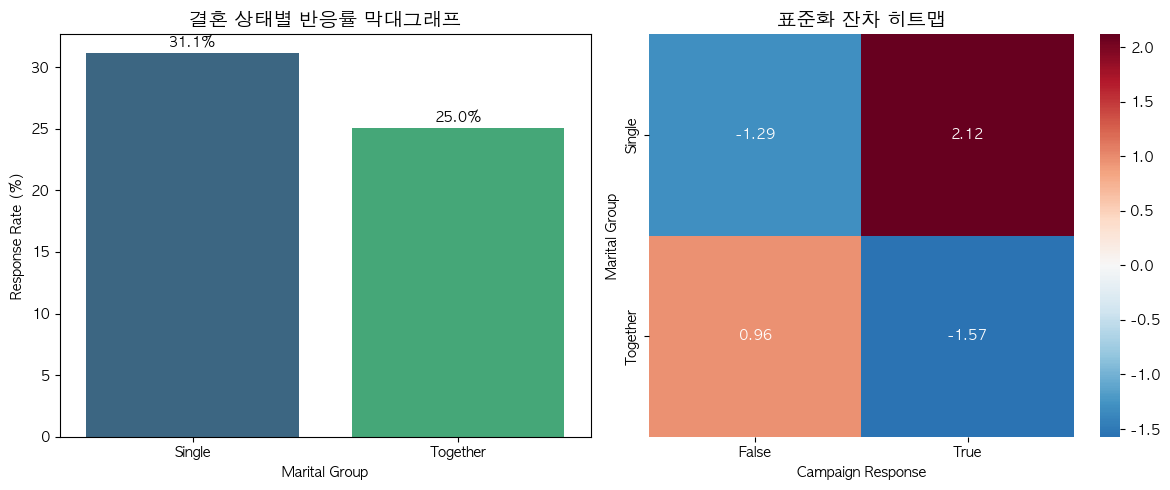

In [630]:
# TODO 4-3(d): (1) 결혼 상태별 반응률 막대그래프 (2) 표준화 잔차 히트맵
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

response_rate = (crosstab_no_margin.iloc[:,1] / crosstab_no_margin.sum(axis=1)) * 100

sns.barplot(x=response_rate.index, y=response_rate.values, ax=axes[0], palette='viridis')
axes[0].set_title('결혼 상태별 반응률 막대그래프', fontsize=14)
axes[0].set_ylabel('Response Rate (%)')
axes[0].set_xlabel('Marital Group')

for i, v in enumerate(response_rate.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

residuals = (crosstab_no_margin.values - expected_ind) / np.sqrt(expected_ind)
resid_df = pd.DataFrame(residuals, index=crosstab_no_margin.index, columns=crosstab_no_margin.columns)

sns.heatmap(resid_df, annot=True, fmt=".2f", cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('표준화 잔차 히트맵', fontsize=14)
axes[1].set_xlabel('Campaign Response')
axes[1].set_ylabel('Marital Group')

plt.tight_layout()
plt.show()


### 문제 4-4. 적합도 검정

3개 구매 채널(Web, Catalog, Store)의 총 구매 비율이 균등하게 분포하는지 검정합니다.

- H₀: 세 채널의 구매 비율이 동일하다 (1/3 : 1/3 : 1/3)
- H₁: 세 채널의 구매 비율이 동일하지 않다

Cohen's w = √(Σ(p_obs - p_exp)² / p_exp)

In [631]:
channel_totals = df[purchase_cols].sum()
channel_names = ['Web', 'Catalog', 'Store']
observed = channel_totals.values

# TODO 4-4(a): 기대빈도(균등) 계산 + 적합도 검정
print(f"== 카이제곱 적합도 검정 ==")
total_purchases = observed.sum()
expected = np.array([total_purchases / len(channel_names)] * 3)
df_merge = pd.DataFrame({'채널 이름' : channel_names, '관측 빈도' : observed, '기대 빈도' : expected})
display(df_merge)

chi2_m, p_m = stats.chisquare(observed, expected)
print(f"카이제곱 통계량: {chi2_m:.4f}, p-value: {p_m:.4f}")

if p_m < 0.05:
    print("=> 귀무가설 기각. 채널 간 구매 비율이 동일하지 않다고 할 수 있다.")
else:
    print("=> 귀무가설 채택. 채널 간 구매 비율이 동일하다고 할 수 있다.")

# TODO 4-4(b): Cohen's w 계산
prob_obs = observed / observed.sum()
prob_exp = expected / observed.sum()
cohens_w = np.sqrt(np.sum((prob_obs - prob_exp)**2 / prob_exp))
print(f"\n(b) Cohen's w = {cohens_w:.3f}")
if cohens_w > 0.3 and cohens_w < 0.5:
    print("    효과크기는 중간효과이다.")

== 카이제곱 적합도 검정 ==


,채널 이름,관측 빈도,기대 빈도
0,Web,9140,9351.333333
1,Catalog,5955,9351.333333
2,Store,12959,9351.333333


카이제곱 통계량: 2630.1063, p-value: 0.0000
=> 귀무가설 기각. 채널 간 구매 비율이 동일하지 않다고 할 수 있다.

(b) Cohen's w = 0.306
    효과크기는 중간효과이다.


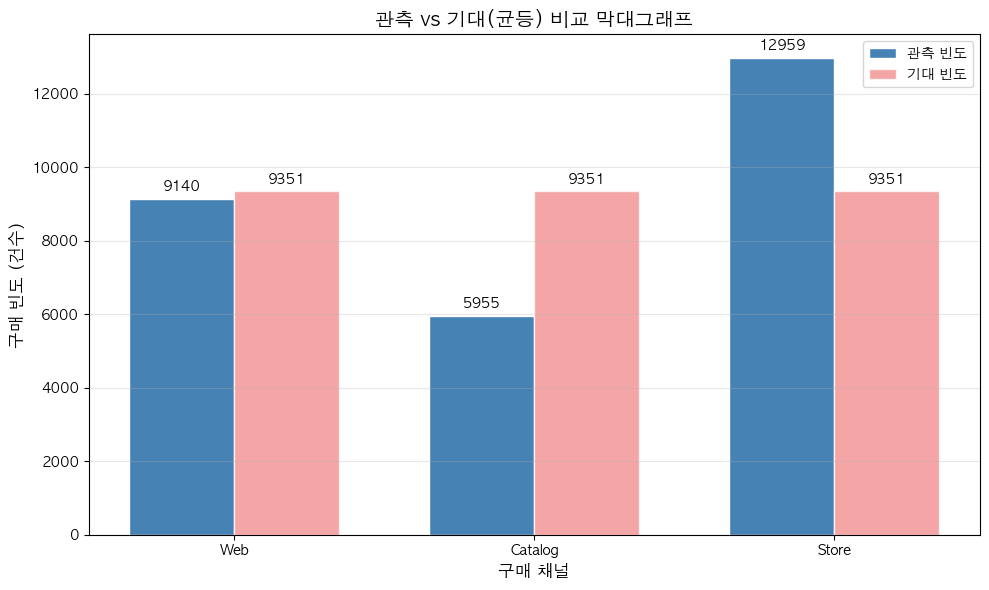

In [632]:
# TODO 4-4(c): 관측 vs 기대(균등) 비교 막대그래프
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(channel_names)) 
width = 0.35

bars1 = ax.bar(x - width/2, observed, width, label='관측 빈도', color='steelblue', edgecolor='white')
bars2 = ax.bar(x + width/2, expected, width, label='기대 빈도', color='lightcoral', edgecolor='white', alpha=0.7)

ax.set_xlabel('구매 채널', fontsize=12)
ax.set_ylabel('구매 빈도 (건수)', fontsize=12)
ax.set_title('관측 vs 기대(균등) 비교 막대그래프', fontsize=14, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(channel_names)

ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + (observed.max()*0.01),
            f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=10)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + (expected.max()*0.01),
            f'{int(bar.get_height())}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

---
## Part 5: 상관분석 / 비율 비교 — "변수 간 관계를 파악하고, 캠페인 효과를 검증할 수 있는가?"

변수 간 상관관계를 분석하고, A/B 테스트로 캠페인 효과를 검증합니다.

### 문제 5-1. 상관분석

6개 변수의 Pearson/Spearman 상관계수를 계산하고 히트맵으로 시각화하세요.
주요 변수 쌍에 대해 유의성 검정도 수행합니다.

In [633]:
corr_vars = ['Income', 'Age', 'Total_Spending', 'Total_Purchases',
             'NumWebVisitsMonth', 'Recency']

# TODO 5-1(a): Pearson/Spearman 상관행렬 계산
pearson_corr = df[corr_vars].corr(method='pearson')
spearman_corr = df[corr_vars].corr(method='spearman')

print("== Pearson 상관행렬 ==")
display(pearson_corr.round(3))

print("\n== Spearman 상관행렬 ==")
display(spearman_corr.round(3))


# TODO 5-1(b): 주요 상관계수 쌍의 유의성 검정 (stats.pearsonr)
print("\n== 주요 상관계수 쌍의 유의성 검정 ==")
pearson_result = pg.pairwise_corr(df, columns=corr_vars, method='pearson')
spearman_result = pg.pairwise_corr(df, columns=corr_vars, method='spearman')

comparison = pd.DataFrame({
    '변수쌍': pearson_result['X'] + ' ↔ ' + pearson_result['Y'],
    'Pearson_r': pearson_result['r'].round(3).values,
    'Spearman_ρ': spearman_result['r'].round(3).values,
    '차이(|P-S|)': abs(pearson_result['r'].values - spearman_result['r'].values).round(4),
    'Pearson_p' : pearson_result['p-unc'].round(4).values,
    'Spearman_p' : spearman_result['p-unc'].round(4).values
})
display(comparison)

significant_corr = comparison[(pearson_result['p-unc'] < 0.05) | (spearman_result['p-unc'] < 0.05)]
print(f"\n통계적으로 유의미한 상관관계 쌍의 개수: {len(significant_corr)}개")

== Pearson 상관행렬 ==


,Income,Age,Total_Spending,Total_Purchases,NumWebVisitsMonth,Recency
Income,1.000,0.199,0.789,0.739,-0.646,0.008
Age,0.199,1.000,0.114,0.173,-0.117,0.019
Total_Spending,0.789,0.114,1.000,0.821,-0.500,0.021
Total_Purchases,0.739,0.173,0.821,1.000,-0.427,0.006
NumWebVisitsMonth,-0.646,-0.117,-0.500,-0.427,1.000,-0.022
Recency,0.008,0.019,0.021,0.006,-0.022,1.000



== Spearman 상관행렬 ==


,Income,Age,Total_Spending,Total_Purchases,NumWebVisitsMonth,Recency
Income,1.000,0.217,0.849,0.777,-0.640,0.010
Age,0.217,1.000,0.158,0.179,-0.129,0.020
Total_Spending,0.849,0.158,1.000,0.908,-0.477,0.020
Total_Purchases,0.777,0.179,0.908,1.000,-0.421,0.012
NumWebVisitsMonth,-0.640,-0.129,-0.477,-0.421,1.000,-0.022
Recency,0.010,0.020,0.020,0.012,-0.022,1.000



== 주요 상관계수 쌍의 유의성 검정 ==


,변수쌍,Pearson_r,Spearman_ρ,차이(|P-S|),Pearson_p,Spearman_p
0,Income ↔ Age,0.199,0.217,0.0177,0.0000,0.0000
1,Income ↔ Total_Spending,0.789,0.849,0.0601,0.0000,0.0000
2,Income ↔ Total_Purchases,0.739,0.777,0.0381,0.0000,0.0000
3,Income ↔ NumWebVisitsMonth,-0.646,-0.640,0.0061,0.0000,0.0000
4,Income ↔ Recency,0.008,0.010,0.0019,0.7114,0.6452
5,Age ↔ Total_Spending,0.114,0.158,0.0441,0.0000,0.0000
6,Age ↔ Total_Purchases,0.173,0.179,0.0063,0.0000,0.0000
7,Age ↔ NumWebVisitsMonth,-0.117,-0.129,0.0119,0.0000,0.0000
8,Age ↔ Recency,0.019,0.020,0.0007,0.3593,0.3419
9,Total_Spending ↔ Total_Purchases,0.821,0.908,0.0874,0.0000,0.0000



통계적으로 유의미한 상관관계 쌍의 개수: 10개


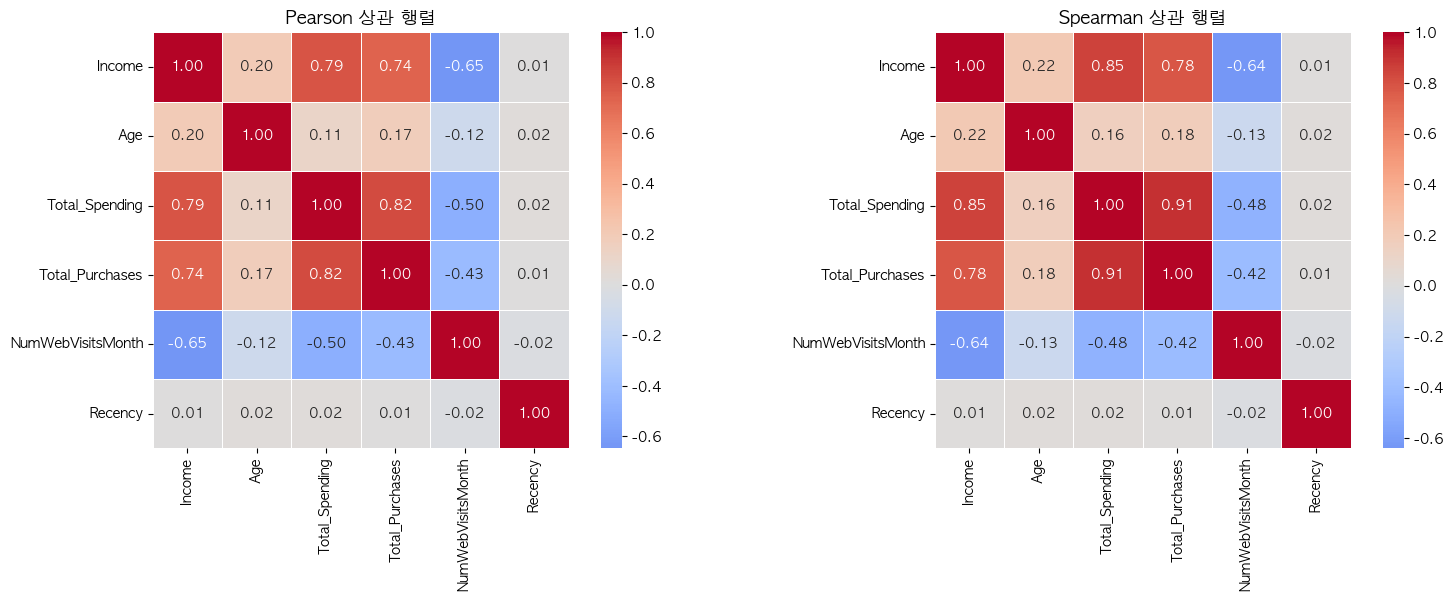

In [634]:
# TODO 5-1(c): 상관행렬 히트맵 (Pearson + Spearman, 1×2 서브플롯)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=0.5, ax=axes[0])
axes[0].set_title('Pearson 상관 행렬', fontsize=13, fontweight='bold')

sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, ax=axes[1])
axes[1].set_title('Spearman 상관 행렬', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

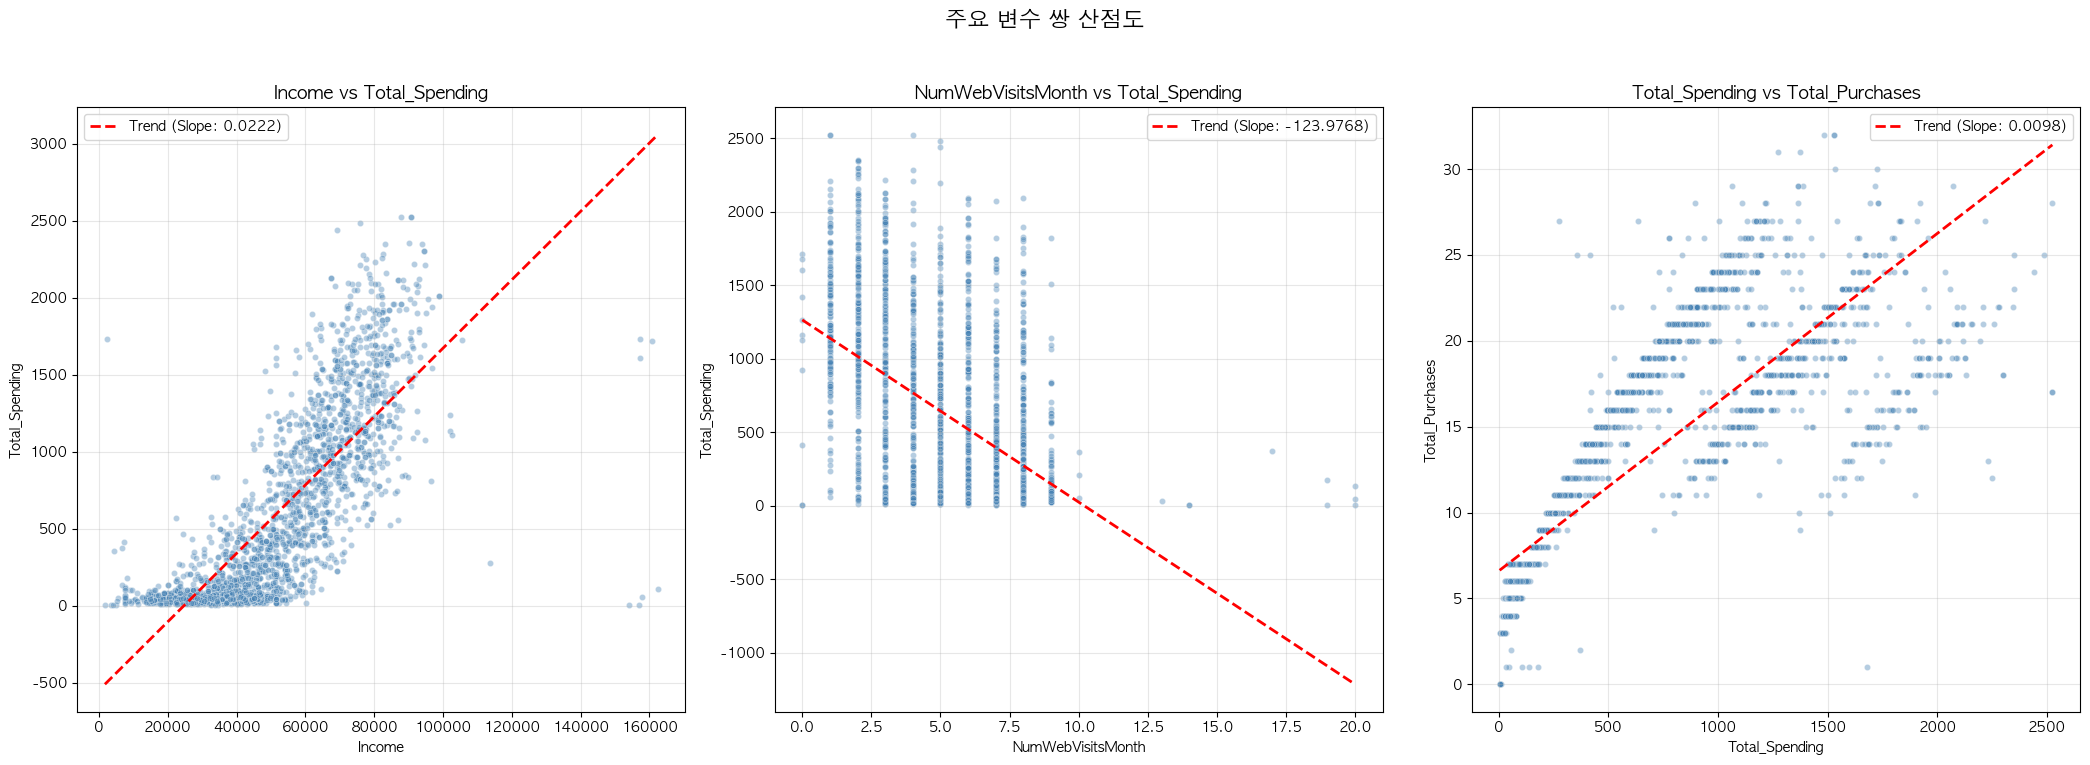

In [635]:
# TODO 5-1(d): 주요 변수 쌍 산점도 + 추세선 (1×3 서브플롯)
# 대상: (Income, Total_Spending), (NumWebVisitsMonth, Total_Spending), (Total_Spending, Total_Purchases)
# np.polyfit()으로 1차 추세선을 그리세요
scatter_pairs = [
    ('Income', 'Total_Spending'),
    ('NumWebVisitsMonth', 'Total_Spending'),
    ('Total_Spending', 'Total_Purchases')
]

fig, axes = plt.subplots(1, 3, figsize=(21, 8))
fig.suptitle('주요 변수 쌍 산점도', fontsize=16, fontweight='bold')

for i, (var_x, var_y) in enumerate(scatter_pairs):
    temp_df = df[[var_x, var_y]]
    x_data = temp_df[var_x]
    y_data = temp_df[var_y]
    
    axes[i].scatter(x_data, y_data, alpha=0.4, s=20, color='steelblue', edgecolors='white', linewidth=0.5)
    
    z = np.polyfit(x_data, y_data, 1)
    p = np.poly1d(z)

    x_range = np.linspace(x_data.min(), x_data.max(), 100)
    axes[i].plot(x_range, p(x_range), "r--", lw=2, label=f'Trend (Slope: {z[0]:.4f})')
    
    axes[i].set_title(f'{var_x} vs {var_y}', fontsize=13)
    axes[i].set_xlabel(var_x)
    axes[i].set_ylabel(var_y)
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### 문제 5-2. 두 그룹 비율 비교 (관찰 연구)

이전 캠페인 반응 경험 유무에 따라 마지막 캠페인(Response) 수락률에 차이가 있는지 검증합니다.

- **Group A**: AcceptedCmp1~5 합계 = 0 (이전 캠페인 무반응)
- **Group B**: AcceptedCmp1~5 합계 ≥ 1 (이전 캠페인 반응 경험)
- **지표**: Response (마지막 캠페인 수락률)
- **검정 방법**: z-비율검정 + Cohen's h + Wilson 신뢰구간

> **주의**: 이 분석은 A/B 테스트가 **아닙니다**. \
> A/B 테스트는 연구자가 참가자를 **무작위로 배정** (Random Assignment)하는 실험입니다. \
> 여기서는 고객이 과거 행동에 의해 스스로 그룹에 배정되었으므로 **관찰 연구**이며, \
> 인과관계를 주장할 수 없습니다.

In [636]:
cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
df['Prior_Response'] = df[cmp_cols].sum(axis=1)

group_a = df[df['Prior_Response'] == 0]
group_b = df[df['Prior_Response'] >= 1]

n_a, n_b = len(group_a), len(group_b)
conv_a = group_a['Response'].sum()
conv_b = group_b['Response'].sum()
rate_a = conv_a / n_a
rate_b = conv_b / n_b

# TODO 5-2(a): z-비율검정
count = [conv_b, conv_a]
nobs = [n_b, n_a]

z_stat, p_val = proportions_ztest(count, nobs, alternative='two-sided')

print(f"(a) z-비율검정")
print(f"    Group A (무반응) 수락률: {rate_a:.4f} (n={n_a})")
print(f"    Group B (반응군) 수락률: {rate_b:.4f} (n={n_b})")
print(f"    z-통계량: {z_stat:.4f}")
print(f"    p-value: {p_val:.4e}")

if p_val < 0.05:
    print("    => 두 그룹 간 수락률 차이는 통계적으로 유의미합니다.")
else:
    print("    => 두 그룹 간 수락률 차이가 유의미하지 않습니다.")


# TODO 5-2(b): Cohen's h 효과 크기
h = proportion_effectsize(rate_a, rate_b)
size_h = '매우 작은' if abs(h) < 0.2 else '작은' if abs(h) < 0.5 else '중간' if abs(h) < 0.8 else '큰'
print(f"\n(b) 효과크기 : Cohen's h = {abs(h):.4f} ({size_h} 효과)")


# TODO 5-2(c): Wilson 신뢰구간
ci_a = proportion_confint(conv_a, n_a, method='wilson')
ci_b = proportion_confint(conv_b, n_b, method='wilson')

print(f"\n(c) Wilson 95% 신뢰구간")
print(f"    Group A (무반응): [{ci_a[0]:.4f}, {ci_a[1]:.4f}]")
print(f"    Group B (반응군): [{ci_b[0]:.4f}, {ci_b[1]:.4f}]")

if ci_b[0] > ci_a[1]:
    print("    => 이전 캠페인에 반응 경험이 있는 그룹의 수락률이 통계적으로 매우 뚜렷하게 높다.")
elif ci_a[0] > ci_b[1]:
    print("    => 이전 캠페인에 반응 경험이 없는 그룹의 수락률이 통계적으로 매우 뚜렷하게 높다.")
else:
    print("    => 두 그룹의 신뢰구간이 일부 겹친다. 비율 차이가 유의미하더라도 그 격차가 상대적으로 크지 않을 수 있다.")

(a) z-비율검정
    Group A (무반응) 수락률: 0.0823 (n=1774)
    Group B (반응군) 수락률: 0.4069 (n=462)
    z-통계량: 17.4357
    p-value: 4.4217e-68
    => 두 그룹 간 수락률 차이는 통계적으로 유의미합니다.

(b) 효과크기 : Cohen's h = 0.8016 (큰 효과)

(c) Wilson 95% 신뢰구간
    Group A (무반응): [0.0704, 0.0960]
    Group B (반응군): [0.3631, 0.4523]
    => 이전 캠페인에 반응 경험이 있는 그룹의 수락률이 통계적으로 매우 뚜렷하게 높다.


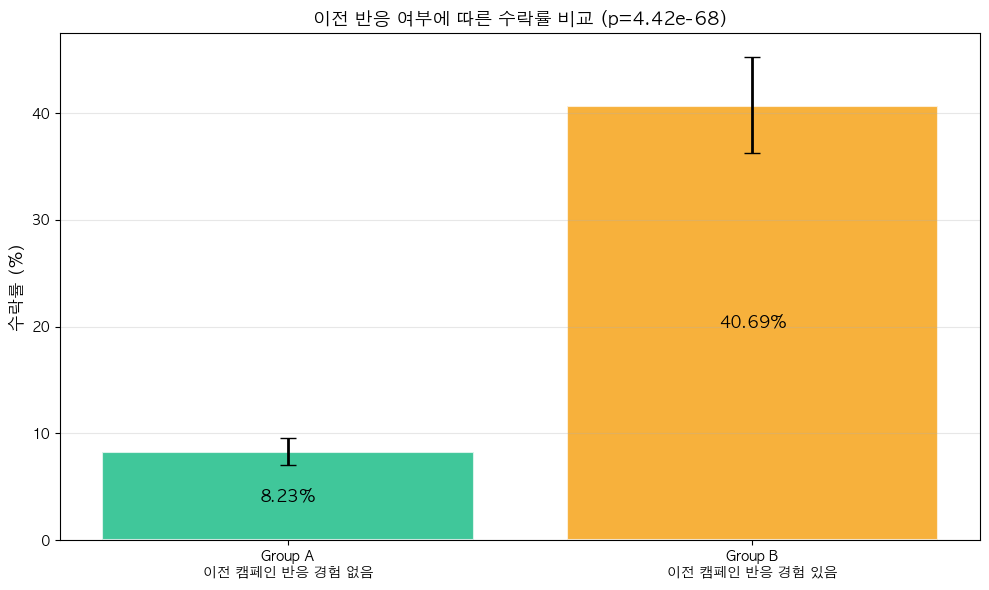

In [637]:
# TODO 5-2(d): 수락률 비교 시각화 (CI 오차막대 포함)
plt.figure(figsize=(10, 6))

rates = [rate_a * 100, rate_b * 100]
bar_colors = ['#10B981', '#F59E0B']
labels = ['Group A\n이전 캠페인 반응 경험 없음', 'Group B\n이전 캠페인 반응 경험 있음']
bars = plt.bar(labels, rates, color=bar_colors, alpha=0.8, edgecolor='white', linewidth=1.5)

yerr = [
    [rates[0] - ci_a[0]*100, rates[1] - ci_b[0]*100],
    [ci_a[1]*100 - rates[0], ci_b[1]*100 - rates[1]] 
]

plt.errorbar(labels, rates, yerr=yerr,
             fmt='none', color='black', capsize=6, linewidth=2)

for bar, r in zip(bars, rates):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height()/2,
             f'{r:.2f}%', ha='center', va='center',
             fontsize=12, fontweight='bold')

plt.ylabel('수락률 (%)', fontsize=12)
plt.title(f'이전 반응 여부에 따른 수락률 비교 (p={p_val:.2e})',
          fontsize=13, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

> ⚠️ **이 분석이 A/B 테스트가 아닌 이유**
>
> A/B 테스트의 본질은 '무작위 배정(Random Assignment)'입니다.
>
> - **A/B 테스트**: 연구자가 참가자를 무작위로 배정 → 인과관계 추론 가능
> - **이 분석**: 고객의 과거 행동으로 그룹이 결정 → 관찰 연구, 인과관계 주장 불가
>
> → 인과관계를 검증하려면 무작위 배정 실험(RCT)을 설계해야 합니다. (문제 5-3)

### 문제 5-3. 진정한 A/B 테스트 설계

새로운 캠페인이 기존 수락률 대비 **2%p** 개선을 가져올 수 있는지 탐지하기 위한
최소 표본 크기를 산정하세요. (α=0.05, Power=0.80)

In [638]:
baseline_rate = df['Response'].mean()
target_rate = baseline_rate + 0.02

# TODO 5-3(a) Cohen's h 계산
print("(a) Cohen's h 계산")
print(f"    기존 전환율 (p₀): {baseline_rate:.0%}")

effect_size = abs(proportion_effectsize(target_rate, baseline_rate))
print(f"    효과크기 (Cohen's h): {effect_size:.4f}")


# TODO 5-3(b): NormalIndPower()로 필요 표본 크기 산정 (α=0.05, Power=0.80, 단측)
power_analysis = NormalIndPower()
sample_size = power_analysis.solve_power(
    effect_size=effect_size,
    alpha=0.05,
    power=0.8,
    alternative='larger'
)
print(f"\n(b) 집단당 필요 표본 크기: {int(np.ceil(sample_size)):,}명")
print(f"    총 필요 표본 크기: {int(np.ceil(sample_size * 2)):,}명")

(a) Cohen's h 계산
    기존 전환율 (p₀): 15%
    효과크기 (Cohen's h): 0.0547

(b) 집단당 필요 표본 크기: 4,138명
    총 필요 표본 크기: 8,276명


---
## Challenge: 종합 분석 보고서

지금까지의 분석을 종합하여 FreshCart 마케팅팀에 제출할 보고서를 작성합니다.

### Challenge 1. 고객 그룹별 특성 분석

`Income_Group` × `Has_Children` 6개 조합에 대해 다음을 포함하는 종합 분석표를 작성하세요:

- 고객 수, 평균 소득, 평균/중앙값 소비, 평균 구매 수, 캠페인 반응률, 웹 방문 수
- 그룹 비교 시각화 (1×3 서브플롯: 평균 소비, 반응률, 고객 수)

,Income_Group,Has_Children,고객수,평균소득,평균소비,중앙값소비,평균구매수,캠페인반응률,평균웹방문수
0,Low,False,115,24380.24,145.01,73.0,6.40,10.43,6.93
1,Low,True,631,29172.88,86.69,54.0,5.67,11.73,6.90
2,Mid,False,80,52209.63,721.24,653.0,15.36,18.75,4.68
3,Mid,True,665,51466.09,426.25,368.0,12.34,9.02,5.87
4,High,False,442,78697.96,1424.02,1383.0,19.22,32.13,2.37
5,High,True,303,71841.61,1033.12,1005.0,19.18,10.23,4.68


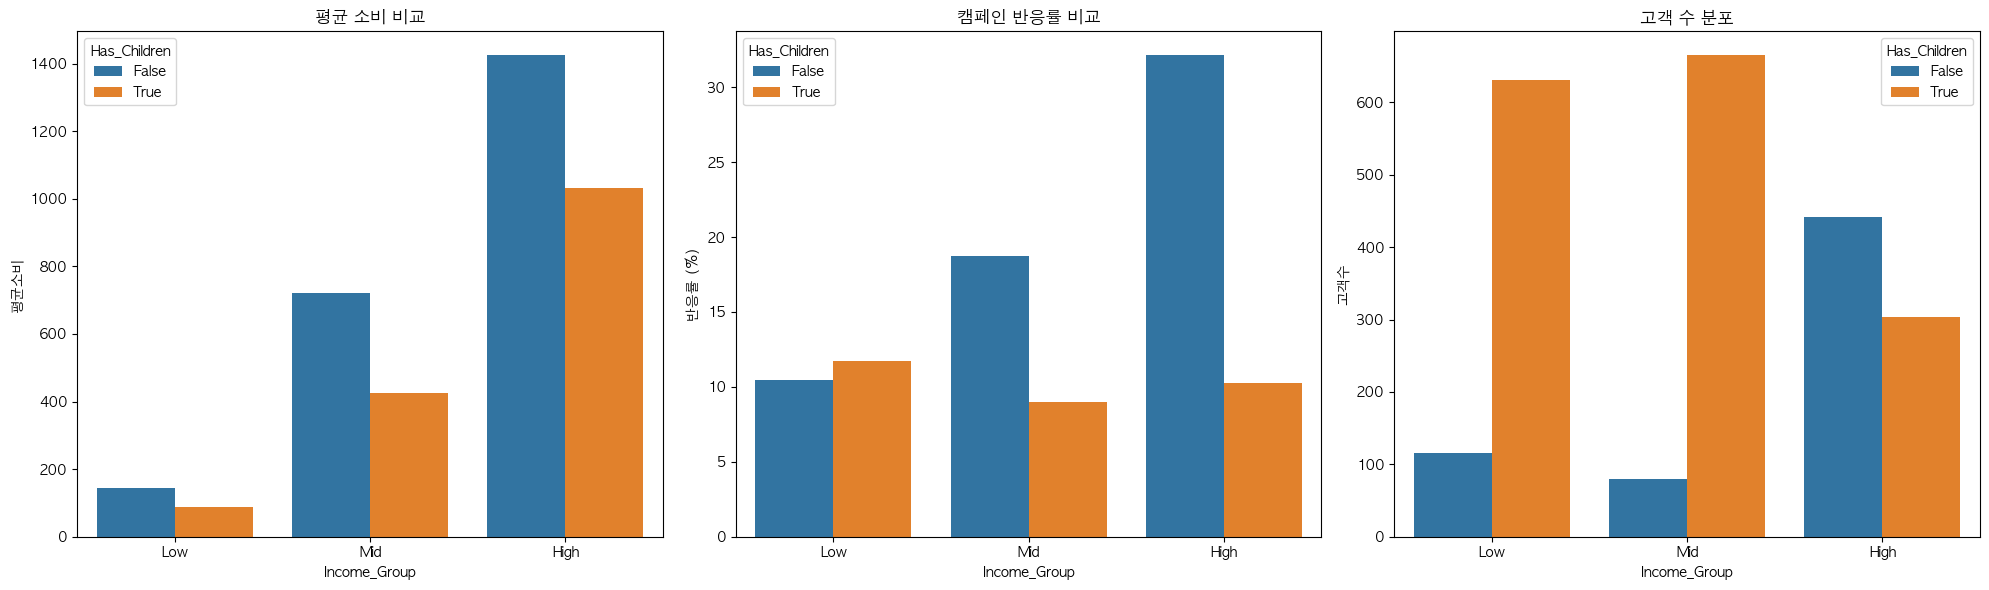

In [639]:
# TODO C-1: 고객 그룹별 특성 분석 종합표 + 시각화
summary_table = (
    df.groupby(["Income_Group", "Has_Children"])
      .agg(
          고객수=("Income", "count"),
          평균소득=("Income", "mean"),
          평균소비=("Total_Spending", "mean"),
          중앙값소비=("Total_Spending", "median"),
          평균구매수=("Total_Purchases", "mean"),
          캠페인반응률=("Response", "mean"),
          평균웹방문수=("NumWebVisitsMonth", "mean")
      )
      .reset_index()
)
summary_table["캠페인반응률"] *= 100

display(summary_table.round(2))

fig, axes = plt.subplots(1, 3, figsize=(20,6))

sns.barplot(
    data=summary_table,
    x="Income_Group",
    y="평균소비",
    hue="Has_Children",
    ax=axes[0]
)
axes[0].set_title("평균 소비 비교")

sns.barplot(
    data=summary_table,
    x="Income_Group",
    y="캠페인반응률",
    hue="Has_Children",
    ax=axes[1]
)
axes[1].set_title("캠페인 반응률 비교")
axes[1].set_ylabel("반응률 (%)")

sns.barplot(
    data=summary_table,
    x="Income_Group",
    y="고객수",
    hue="Has_Children",
    ax=axes[2]
)
axes[2].set_title("고객 수 분포")

plt.tight_layout()
plt.show()

### Challenge 2. 비즈니스 제안서

분석 결과를 종합하여 다음을 포함하는 제안서를 작성하세요:

1. **타겟 고객**: 어떤 그룹를 우선 집중 공략해야 하는가? (근거 포함)
2. **채널 전략**: 소득 그룹별 최적 마케팅 채널은?
3. **기대 효과**: 집중 공략 기반 예상 개선 효과
4. **한계점**: 분석의 한계와 추가 필요 데이터

In [640]:
# TODO C-2: 비즈니스 제안서 작성
print("1. 타겟 고객")
print("   1차 타겟: High Income × 무자녀 그룹")
print("    => 평균 소비가 가장 높고, 캠페인 반응률 또한 유의하게 높음")
print("    => Welch t-test 결과 자녀 유무에 따른 소비 차이 유의")
print("   2차 타겟: 이전 캠페인 반응 경험 고객")
print("    => 수락률이 유의하게 높으며, 리타겟팅 전략에 적합")

print("\n2. 채널 전략")
print("   High Income 그룹: 소비 가장 높음 + 평균 웹 방문 수 높음 + 캠페인 반응률 상대적으로 높음\
      \n    => 개인화 이메일 + 웹 리타겟팅")
print("   Mid Income 그룹: 소비 중간 + 반응률 중간\
      \n    => 프로모션 중심 이메일 + 추천 상품 전략")
print("   Low Income 그룹: 소비 가장 낮음 + 반응률 낮음\
      \n    => 가격 할인 및 쿠폰 중심 마케팅")

print("\n3. 기대 효과")
print("   2%p 수락률 개선 목표 설정")
print("   작은 효과(d=0.2) 탐지를 위해 그룹당 약 394명 필요")
print("   현재 표본 규모는 충분하며, 집중 타겟팅 시 수락률 2~4%p 개선 기대")

print("\n4. 한계점")
print("   관측 데이터 기반 분석으로 인과관계 확정 불가 (A/B 테스트 필요)")
print("   캠페인 콘텐츠 차이(메시지/할인 강도/채널 효과) 고려하지 않음")
print("   캠페인 콘텐츠 차이, 고객 세션 시간, 상품 선호도, 장바구니 이탈률 등 추가로 필요")

1. 타겟 고객
   1차 타겟: High Income × 무자녀 그룹
    => 평균 소비가 가장 높고, 캠페인 반응률 또한 유의하게 높음
    => Welch t-test 결과 자녀 유무에 따른 소비 차이 유의
   2차 타겟: 이전 캠페인 반응 경험 고객
    => 수락률이 유의하게 높으며, 리타겟팅 전략에 적합

2. 채널 전략
   High Income 그룹: 소비 가장 높음 + 평균 웹 방문 수 높음 + 캠페인 반응률 상대적으로 높음      
    => 개인화 이메일 + 웹 리타겟팅
   Mid Income 그룹: 소비 중간 + 반응률 중간      
    => 프로모션 중심 이메일 + 추천 상품 전략
   Low Income 그룹: 소비 가장 낮음 + 반응률 낮음      
    => 가격 할인 및 쿠폰 중심 마케팅

3. 기대 효과
   2%p 수락률 개선 목표 설정
   작은 효과(d=0.2) 탐지를 위해 그룹당 약 394명 필요
   현재 표본 규모는 충분하며, 집중 타겟팅 시 수락률 2~4%p 개선 기대

4. 한계점
   관측 데이터 기반 분석으로 인과관계 확정 불가 (A/B 테스트 필요)
   캠페인 콘텐츠 차이(메시지/할인 강도/채널 효과) 고려하지 않음
   캠페인 콘텐츠 차이, 고객 세션 시간, 상품 선호도, 장바구니 이탈률 등 추가로 필요


---
## 수고하셨습니다!

설날 연휴 따뜻하고 복 가득한 시간 보내요! 💛